<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/bloodmnist-cnn-regularisation-cam.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Blood cell images

This notebook repeats the whole path of the lectures on **one biological data set**: microscope images of human blood cells (BloodMNIST). Each model is motivated by the failure of the previous one. We start with a dense (feed-forward) network on the flattened image, with eight outputs and the categorical cross-entropy loss. Flattening discards the information which pixels are neighbours, so we turn next to a small convolutional neural network (CNN), built from convolutions, max pooling and feature maps. A larger CNN does better but begins to *overfit*, and this brings us to regularisation: an L2 penalty (weight decay), dropout, batch normalisation, data augmentation and early stopping. Finally, a CNN that ends with global average pooling (GAP) gives us class activation maps (CAM), which show which part of the image is the evidence for a class. A table at the end collects the training, validation and test accuracy of all models.

In the last part the same network and the same code are applied to a **second data set from a different field**, satellite images of the Earth's surface (EuroSAT), to show that only the data and a few choices that depend on the data change.

### MNIST and MedMNIST

MNIST, the *Modified National Institute of Standards and Technology* database, consists of $70\,000$ grey images of $28\times28$ pixels showing hand-written digits $0\dots9$, prepared by Y. LeCun, C. Cortes and C. Burges from data collected by the US institute NIST. It is the "hello world" of deep learning (Lab 009).

MedMNIST borrows the name and the idea. It is a collection of biomedical image data sets brought to the same simple form as MNIST: small images of a fixed size, a fixed split into training, validation and test parts, and one file per data set. Version 2 contains 12 data sets of 2D images (pathology slides, chest X-rays, skin lesions, retina scans, blood cells, ...) and 6 data sets of 3D images. The images are provided at $28\times28$ pixels and, in the larger version, at $64$, $128$ and $224$ pixels.
J. Yang et al., *Scientific Data* **10**, 41 (2023), [doi:10.1038/s41597-022-01721-8](https://doi.org/10.1038/s41597-022-01721-8), <https://medmnist.com> (licence CC BY 4.0).

### BloodMNIST

BloodMNIST is built from the images of A. Acevedo et al., *A dataset of microscopic peripheral blood cell images for development of automatic recognition systems*, *Data in Brief* **30**, 105474 (2020), [doi:10.1016/j.dib.2020.105474](https://doi.org/10.1016/j.dib.2020.105474). They are $17\,092$ microscope images of *individual normal cells* from peripheral blood, acquired with the analyser CellaVision DM96 in the Core Laboratory of the Hospital Clinic of Barcelona. The blood comes from individuals without infection, haematologic or oncologic disease, and free of any pharmacologic treatment at the moment of blood collection.

Each sample is one colour image of one cell. The original images have $360\times363$ pixels; MedMNIST crops the central $200\times200$ pixels and resizes them. The label is the cell type, one of eight groups assigned by expert clinical pathologists and stored as an integer $0\dots7$. The data come split into $11\,959$ training, $1\,712$ validation and $3\,421$ test images, in the ratio 7 : 1 : 2.

| label | cell type | what it is |
|---|---|---|
| 0 | basophil | white blood cell (granulocyte) with large dark granules that often hide the nucleus |
| 1 | eosinophil | white blood cell (granulocyte) with a two-lobed nucleus and pink-orange granules |
| 2 | erythroblast | immature red blood cell that still has a nucleus |
| 3 | immature granulocyte | precursors of granulocytes: promyelocytes, myelocytes and metamyelocytes |
| 4 | lymphocyte | small white blood cell; a round nucleus fills most of the cell |
| 5 | monocyte | the largest white blood cell, with a folded or kidney-shaped nucleus |
| 6 | neutrophil | the most common white blood cell (granulocyte), with a nucleus of several lobes |
| 7 | platelet | small cell fragment without a nucleus, involved in blood clotting |

Our task is to predict the type of a cell from its image. This is *supervised learning*, a *classification into 8 classes*.

> The notebook also runs in Google Colab:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*.
> 2. Switch on a GPU: *Runtime → Change runtime type → T4 GPU*; the whole notebook then takes a few minutes. On a CPU it also runs (the outputs stored in this file were computed on a laptop CPU in about 36 minutes, see the times printed per epoch); to make it faster set `SIZE = 28` in the configuration cell.
> 3. Run cells one by one with **Shift + Enter**, *in order*.
> 4. The data (about 150 MB for $64\times64$, 35 MB for $28\times28$) are downloaded once into the folder `data/`.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)                    # fixes the random initial parameters
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "  NumPy", np.__version__, "  device:", device)

PyTorch 2.9.0+cpu   NumPy 2.1.3   device: cpu


## 0. Image size and training length

All numbers that control the length of the calculation are collected in one cell: the image size, the mini-batch size and the numbers of epochs. Changing them here changes the whole notebook consistently.

In [2]:
SIZE = 64            # image size in pixels: 64 (default) or 28 (fast, for a CPU)
BATCH = 128          # mini-batch size
EPOCHS_DENSE = 10    # epochs for the dense network
EPOCHS_CNN = 10      # epochs for each CNN
LR = 1e-3            # learning rate of the Adam optimiser

<hr/>
## 1. The data

### 1.1 Download
MedMNIST stores each data set as one NumPy archive (`.npz`) on Zenodo. `urllib.request.urlretrieve(url, path)` downloads a file and saves it on disk;
a file that is already there is not downloaded again.

The same data can be obtained with the package `medmnist` (`pip install medmnist`, then `from medmnist import BloodMNIST`); reading the file directly shows what is inside.

In [3]:
DATA_DIR = "data"
fname = "bloodmnist.npz" if SIZE == 28 else f"bloodmnist_{SIZE}.npz"
url = f"https://zenodo.org/records/10519652/files/{fname}?download=1"
path = os.path.join(DATA_DIR, fname)
os.makedirs(DATA_DIR, exist_ok=True)
def download(url, path, tries=8):
    # Download url to path unless the file exists. The Zenodo server sometimes answers "504 Gateway Time-out": then wait and try again.
    if os.path.exists(path):
        return
    for attempt in range(1, tries + 1):
        try:
            print(f"downloading {url} (attempt {attempt})")
            urllib.request.urlretrieve(url, path + ".part")
            os.replace(path + ".part", path)
            return
        except Exception as error:
            print("  failed:", error)
            time.sleep(15)
    raise RuntimeError("download failed; try again later, or use: pip install medmnist")

download(url, path)
print(path, f"{os.path.getsize(path) / 1e6:.1f} MB")

data = np.load(path)
for key in data.files:
    print(f"{key:14s} shape {data[key].shape}  dtype {data[key].dtype}")

data/bloodmnist_64.npz 156.3 MB


train_images   shape (11959, 64, 64, 3)  dtype uint8
train_labels   shape (11959, 1)  dtype uint8


val_images     shape (1712, 64, 64, 3)  dtype uint8
val_labels     shape (1712, 1)  dtype uint8


test_images    shape (3421, 64, 64, 3)  dtype uint8
test_labels    shape (3421, 1)  dtype uint8


The archive contains six arrays: images and labels for the **training**, **validation** and **test** part. An image is an array `(SIZE, SIZE, 3)` of unsigned bytes, three colour channels (red, green, blue) in which every pixel is an integer $0\dots255$; a label is an integer $0\dots7$, the cell type.

The three parts have different roles. The network is *trained* on the training set, the *validation* set monitors the training (overfitting, early stopping), and the *test* set is used only once, at the end, to report the final accuracy.

In [4]:
X_train, y_train = data["train_images"], data["train_labels"].ravel()
X_val,   y_val   = data["val_images"],   data["val_labels"].ravel()
X_test,  y_test  = data["test_images"],  data["test_labels"].ravel()

class_names = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]
N_CLASSES = len(class_names)
print("training:", X_train.shape, " validation:", X_val.shape, " test:", X_test.shape)
print("pixel values from", X_train.min(), "to", X_train.max())

training: (11959, 64, 64, 3)  validation: (1712, 64, 64, 3)  test: (3421, 64, 64, 3)
pixel values from 8 to 255


### 1.2 Example images

Four training images of every class. Compare them with the descriptions in the table above: the size of the cell, the shape of the nucleus and the granules are the features a pathologist looks at.

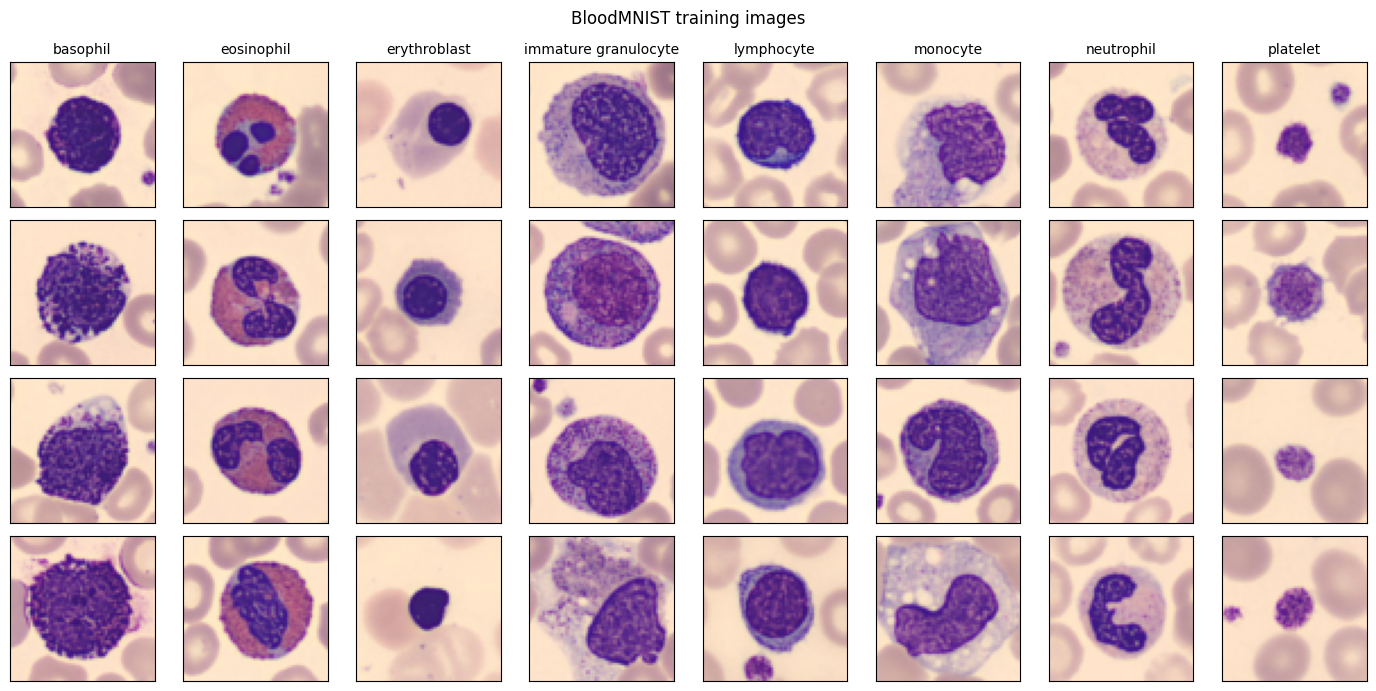

In [5]:
fig, axes = plt.subplots(4, N_CLASSES, figsize=(14, 7))
for c in range(N_CLASSES):
    positions = np.flatnonzero(y_train == c)[:4]            # first four training images of class c
    for row, p in enumerate(positions):
        axes[row, c].imshow(X_train[p])
        axes[row, c].set_xticks([]); axes[row, c].set_yticks([])
    axes[0, c].set_title(class_names[c], fontsize=10)
fig.suptitle("BloodMNIST training images")
fig.tight_layout(); plt.show()

One image is nothing but a block of numbers. The first training image, its label, and the red, green and blue values of a $4\times4$ corner:

shape: (64, 64, 3)   label: 7 = platelet
red channel, top-left 4 x 4 pixels:
 [[254 254 253 253]
 [254 254 253 253]
 [254 254 254 253]
 [254 254 254 253]]
one pixel (row 30, column 30): R, G, B = [104  46 143]


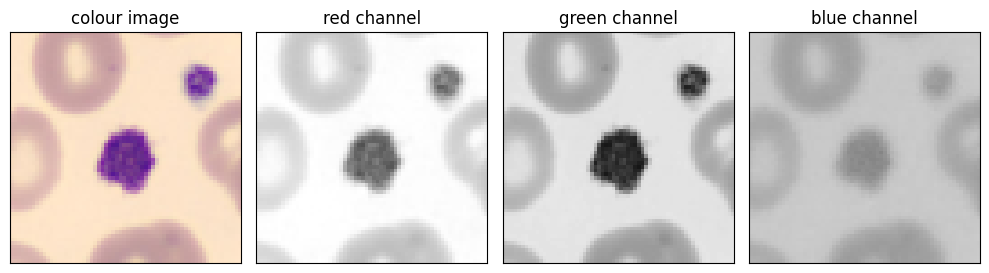

In [6]:
image, label = X_train[0], y_train[0]
print("shape:", image.shape, "  label:", label, "=", class_names[label])
print("red channel, top-left 4 x 4 pixels:\n", image[:4, :4, 0])
print("one pixel (row 30, column 30): R, G, B =", image[30 * SIZE // 64, 30 * SIZE // 64])

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
axes[0].imshow(image); axes[0].set_title("colour image")
for k, name in enumerate(["red", "green", "blue"]):
    axes[k + 1].imshow(image[:, :, k], cmap="gray", vmin=0, vmax=255); axes[k + 1].set_title(name + " channel")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

### 1.3 Images per class

The classes are **not balanced**: neutrophils make up $19.5\%$ of the training set, basophils and lymphocytes only $7.1\%$ each. This matters when we read the accuracy. A network that always answers with the most frequent class is already right in a fraction of the cases equal to the share of that class, here $19.5\%$, and every model below has to be compared with this number rather than with $1/8$.

basophil                 852  ( 7.1%)
eosinophil              2181  (18.2%)
erythroblast            1085  ( 9.1%)
immature granulocyte    2026  (16.9%)
lymphocyte               849  ( 7.1%)
monocyte                 993  ( 8.3%)
neutrophil              2330  (19.5%)
platelet                1643  (13.7%)

always answering 'neutrophil' gives accuracy 19.5% on the training set


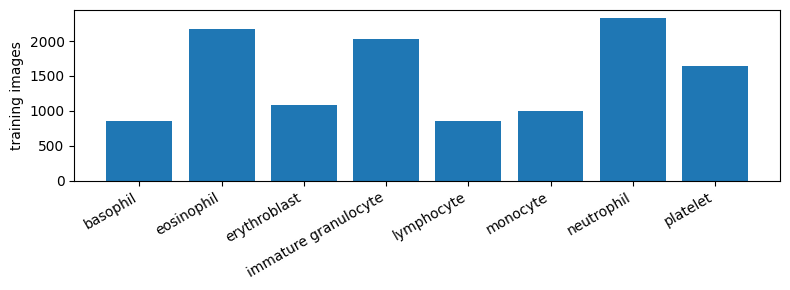

In [7]:
counts = np.bincount(y_train, minlength=N_CLASSES)
for name, n in zip(class_names, counts):
    print(f"{name:22s} {n:5d}  ({100 * n / len(y_train):4.1f}%)")
print(f"\nalways answering '{class_names[counts.argmax()]}' gives accuracy {100 * counts.max() / len(y_train):.1f}% on the training set")

plt.figure(figsize=(8, 3))
plt.bar(range(N_CLASSES), counts)
plt.xticks(range(N_CLASSES), class_names, rotation=30, ha="right"); plt.ylabel("training images")
plt.tight_layout(); plt.show()

### 1.4 Image tensors

Three operations prepare the images for a network. The bytes $0\dots255$ are converted to real numbers $0\dots1$; the axes are reordered from `(N, height, width, channel)` to `(N, channel, height, width)`, the convention of PyTorch; and every colour channel is **standardised**, that is, its mean is subtracted and the result divided by its standard deviation. The mean and the standard deviation are computed on the *training* set only, so that nothing from the validation and test images enters the preparation of the data.

In [8]:
mean = X_train.reshape(-1, 3).mean(axis=0) / 255            # one number per colour channel
std  = X_train.reshape(-1, 3).std(axis=0) / 255
print("channel means:", np.round(mean, 3), "  standard deviations:", np.round(std, 3))

def to_tensor(X):
    x = torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    m = torch.tensor(mean, dtype=torch.float32)[:, None, None]
    s = torch.tensor(std, dtype=torch.float32)[:, None, None]
    return ((x - m) / s).to(device)

Xtr, Xva, Xte = to_tensor(X_train), to_tensor(X_val), to_tensor(X_test)
ytr = torch.tensor(y_train, dtype=torch.long, device=device)
yva = torch.tensor(y_val,   dtype=torch.long, device=device)
yte = torch.tensor(y_test,  dtype=torch.long, device=device)
print("training tensor:", tuple(Xtr.shape), Xtr.dtype)

channel means: [0.796 0.66  0.696]   standard deviations: [0.223 0.255 0.095]


training tensor: (11959, 3, 64, 64) torch.float32


<hr/>
## 2a. Softmax and cross-entropy

A classification network returns one real number per class, the **score** (or *logit*) $S_c$. Two operations turn the scores into a loss. The **softmax** turns scores into probabilities,
$$q_c = \frac{e^{S_c}}{\sum_{c'} e^{S_{c'}}}, \tag{1}$$
which are positive and sum to one. The **categorical cross-entropy** then compares them with the true class $t$,
$$\mathcal{L} = -\ln q_t . \tag{2}$$
It is $0$ if the network gives probability $1$ to the true class and grows without bound as $q_t$ approaches 0.

Example with three classes: we compute the probabilities and the loss directly from these formulas and compare the loss with `F.cross_entropy`, the PyTorch function used in the rest of the notebook. The two values agree, $0.241311$, up to the rounding of 32-bit floating-point numbers. Had the true class been the least likely one, the loss would have been $3.24$.

In [9]:
scores = torch.tensor([[2.0, 0.5, -1.0]])        # scores of ONE image for 3 classes
true_class = torch.tensor([0])

q = torch.exp(scores) / torch.exp(scores).sum()   # softmax written out
loss_explicit = -torch.log(q[0, true_class])
print("probabilities:", q.numpy().round(3), "  sum:", q.sum().item())
print("loss, written out   :", loss_explicit.item())
print("F.cross_entropy     :", F.cross_entropy(scores, true_class).item())
print("if the true class were 2:", F.cross_entropy(scores, torch.tensor([2])).item())

probabilities: [[0.786 0.175 0.039]]   sum: 1.0
loss, written out   : 0.24131131172180176
F.cross_entropy     : 0.24131132662296295
if the true class were 2: 3.2413113117218018


For a network that knows nothing, all 8 classes get probability $1/8$ and the loss is
$$-\ln\tfrac18=\ln 8 \approx 2.08. \tag{3}$$
This is the value to expect before training,
and the first check of any new training loop.

In [10]:
print("ln 8 =", np.log(8))

ln 8 = 2.0794415416798357


<hr/>
## 2b. The training loop

The same loop is used for every model in this notebook, so that the models can be compared fairly. One **epoch** is one pass over the training set in mini-batches. For every mini-batch the network first computes the class scores (*logits*) in the forward pass; the loss, the **categorical cross-entropy** between the softmax of the scores and the true class, is evaluated; the backward pass computes the gradients of the loss with respect to all parameters; and the optimiser (Adam) updates the parameters. `F.cross_entropy(scores, labels)` applies the softmax itself, so the models below end with a plain linear layer.

The function has two options that we need later, in the regularisation part: `weight_decay` sets the strength $\lambda$ of the **L2 penalty**, and `augment` is a function that modifies each mini-batch (**data augmentation**). In addition, the function always remembers the parameters with the **lowest validation loss**, which is what **early stopping** needs.

In [11]:
def evaluate(model, X, y):
    # Return (accuracy, mean loss) of the model on the data X, y. No gradients are needed here.
    model.eval()                                             # switches dropout off and batch norm to its stored statistics
    correct, loss_sum = 0, 0.0
    with torch.no_grad():
        for k in range(0, len(X), 500):
            scores = model(X[k:k + 500])
            correct += (scores.argmax(dim=1) == y[k:k + 500]).sum().item()
            loss_sum += F.cross_entropy(scores, y[k:k + 500], reduction="sum").item()
    return correct / len(X), loss_sum / len(X)

def train(model, epochs, lr=LR, weight_decay=0.0, augment=None, verbose=True, data=None):
    # Train the model; return the history (one dictionary per epoch) and the best parameters seen on the validation set.
    # data = (training images, training labels, validation images, validation labels); default: the blood-cell tensors.
    Xtr_, ytr_, Xva_, yva_ = data if data is not None else (Xtr, ytr, Xva, yva)
    model.to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_val_loss, best_state = [], float("inf"), None
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()                                        # training mode: dropout active, batch norm uses the mini-batch
        permutation = torch.randperm(len(Xtr_), device=device)
        for k in range(0, len(Xtr_), BATCH):
            idx = permutation[k:k + BATCH]
            x, y = Xtr_[idx], ytr_[idx]
            if augment is not None:
                x = augment(x)
            loss = F.cross_entropy(model(x), y)
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
        train_acc, train_loss = evaluate(model, Xtr_, ytr_)
        val_acc, val_loss = evaluate(model, Xva_, yva_)
        history.append(dict(epoch=epoch, train_acc=train_acc, train_loss=train_loss, val_acc=val_acc, val_loss=val_loss))
        if val_loss < best_val_loss:
            best_val_loss, best_state = val_loss, copy.deepcopy(model.state_dict())
        if verbose:
            print(f"epoch {epoch:2d}: training loss {train_loss:.3f} acc {train_acc:.3f} | "
                  f"validation loss {val_loss:.3f} acc {val_acc:.3f}  ({time.time() - t0:.0f} s)")
    return history, best_state

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

def plot_history(history, title):
    epochs = [h["epoch"] for h in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(epochs, [h["train_loss"] for h in history], "o-", label="training")
    axes[0].plot(epochs, [h["val_loss"] for h in history], "s-", label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend()
    axes[1].plot(epochs, [h["train_acc"] for h in history], "o-", label="training")
    axes[1].plot(epochs, [h["val_acc"] for h in history], "s-", label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title); fig.tight_layout(); plt.show()

results = {}                                                 # name -> accuracies, filled model by model
def record(name, model, history):
    results[name] = dict(parameters=count_parameters(model),
                         train=evaluate(model, Xtr, ytr)[0], val=evaluate(model, Xva, yva)[0], test=evaluate(model, Xte, yte)[0])
    r = results[name]
    print(f"{name}: {r['parameters']} parameters | training {100 * r['train']:.1f}%  validation {100 * r['val']:.1f}%  test {100 * r['test']:.1f}%")

<hr/>
## 3. Model A: a dense network on the flattened image

The first attempt is the network of the MNIST example: the image is **flattened** into one long vector of $\text{SIZE}\cdot\text{SIZE}\cdot3$ numbers,
followed by one hidden layer of $21$ sigmoid nodes and an output layer with $8$ nodes, one per class.

Flattening throws away the information which pixels are neighbours: any fixed permutation of the pixels would give the network exactly the same task.

In [12]:
model_A = nn.Sequential(
    nn.Flatten(),                                # (N, 3, SIZE, SIZE) -> (N, 3*SIZE*SIZE)
    nn.Linear(3 * SIZE * SIZE, 21), nn.Sigmoid(),
    nn.Linear(21, N_CLASSES))                    # 8 class scores; the softmax is inside the loss
print(model_A)
for name, p in model_A.named_parameters():
    print(f"  {name:10s} {str(tuple(p.shape)):14s} {p.numel():7d} parameters")
print("total:", count_parameters(model_A), "=", 3 * SIZE * SIZE, "* 21 + 21 + 21 * 8 + 8")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=21, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=21, out_features=8, bias=True)
)
  1.weight   (21, 12288)     258048 parameters
  1.bias     (21,)               21 parameters
  3.weight   (8, 21)            168 parameters
  3.bias     (8,)                 8 parameters
total: 258245 = 12288 * 21 + 21 + 21 * 8 + 8


Before training we send one mini-batch through the network. The output has one row per image and one column per class. The loss should be close to $\ln 8$ and the accuracy close to chance, and indeed the untrained network gives a loss of $2.068$ and a validation accuracy of $18.2\%$.

In [13]:
model_A.to(device)
x_batch, y_batch = Xtr[:BATCH], ytr[:BATCH]
scores = model_A(x_batch)
print("input", tuple(x_batch.shape), " -> scores", tuple(scores.shape))
print("loss of the untrained network:", F.cross_entropy(scores, y_batch).item())
print("accuracy of the untrained network on the validation set:", evaluate(model_A, Xva, yva)[0])

input (128, 3, 64, 64)  -> scores (128, 8)
loss of the untrained network: 2.068084716796875
accuracy of the untrained network on the validation set: 0.1822429906542056


Model A is trained for `EPOCHS_DENSE` epochs; each line reports the loss and the accuracy on the training and the validation set.

epoch  1: training loss 1.472 acc 0.579 | validation loss 1.477 acc 0.576  (0 s)


epoch  2: training loss 1.276 acc 0.640 | validation loss 1.283 acc 0.634  (0 s)


epoch  3: training loss 1.122 acc 0.696 | validation loss 1.129 acc 0.694  (0 s)


epoch  4: training loss 1.023 acc 0.709 | validation loss 1.035 acc 0.701  (0 s)


epoch  5: training loss 0.924 acc 0.734 | validation loss 0.933 acc 0.730  (0 s)


epoch  6: training loss 0.832 acc 0.740 | validation loss 0.846 acc 0.736  (0 s)


epoch  7: training loss 0.797 acc 0.743 | validation loss 0.808 acc 0.738  (0 s)


epoch  8: training loss 0.730 acc 0.752 | validation loss 0.751 acc 0.739  (0 s)


epoch  9: training loss 0.693 acc 0.773 | validation loss 0.706 acc 0.774  (0 s)


epoch 10: training loss 0.663 acc 0.783 | validation loss 0.706 acc 0.752  (0 s)


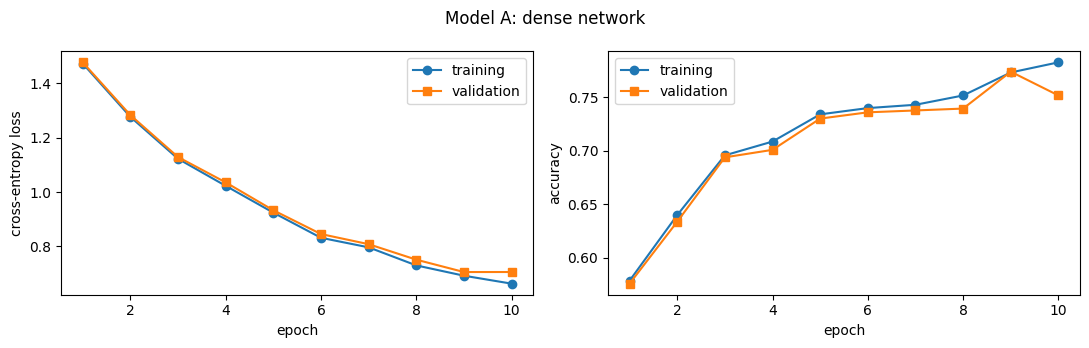

A: dense network: 258245 parameters | training 78.3%  validation 75.2%  test 75.6%


In [14]:
history_A, _ = train(model_A, EPOCHS_DENSE)
plot_history(history_A, "Model A: dense network")
record("A: dense network", model_A, history_A)

After 10 epochs the dense network reaches $78.3\%$ on the training set, $75.2\%$ on the validation set and $75.6\%$ on the test set, far above the $19.5\%$ of the trivial answer. The flattened pixels do carry information: the size of the cell, the amount of dark nucleus, the colours. The training accuracy is three points above the validation accuracy, the first, mild sign of overfitting. Three cells out of four is the reference for everything that follows.

<hr/>
## 4. Model B: a small convolutional network

A **convolutional layer** slides small kernels ($3\times3$ here) over the image. Each kernel has its own trainable weights and produces one **feature map**: an image that tells *where* the pattern of that kernel was found. The same kernel is used at every position, so the number of parameters does not depend on the image size.

In PyTorch, `nn.Conv2d(3, 32, kernel_size=3, padding=1)` is a layer with 3 input channels (RGB) and 32 kernels, hence 32 feature maps; `padding=1` keeps the size `SIZE × SIZE`. It is followed by `nn.MaxPool2d(2)`, which keeps the maximum of every $2\times2$ block and so halves width and height. This is the small CNN of the lecture on CIFAR-10 (sigmoid activations, one convolutional layer).

### 4.0 Convolution and pooling on a small example

A $5\times5$ image with a vertical edge, and a $3\times3$ Sobel kernel that detects vertical edges. The output at one position is the sum of the products of the kernel with the $3\times3$ patch under it. We compute the top-left output directly from this definition, obtain $4$, and compare with `F.conv2d`, which gives the same value.

In [15]:
image5 = torch.tensor([[0, 0, 1, 1, 1]] * 5, dtype=torch.float32)          # dark on the left, bright on the right
sobel = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32)
print("image:\n", image5.numpy())
print("kernel:\n", sobel.numpy())

patch = image5[0:3, 0:3]                                                  # the 3 x 3 patch in the top-left corner
print("top-left output, explicit sum:", (patch * sobel).sum().item())

out = F.conv2d(image5[None, None], sobel[None, None])                      # shapes (1, 1, 5, 5) and (1, 1, 3, 3)
print("F.conv2d, no padding -> shape", tuple(out.shape[2:]), "\n", out[0, 0].numpy())
out_same = F.conv2d(image5[None, None], sobel[None, None], padding=1)
print("with padding=1 the size is kept:", tuple(out_same.shape[2:]))
print("max pooling 2 x 2 of the 3 x 3 output (the last row and column are dropped):", F.max_pool2d(out, 2)[0, 0].numpy())

image:
 [[0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]]
kernel:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
top-left output, explicit sum: 4.0
F.conv2d, no padding -> shape (3, 3) 
 [[4. 4. 0.]
 [4. 4. 0.]
 [4. 4. 0.]]
with padding=1 the size is kept: (5, 5)
max pooling 2 x 2 of the 3 x 3 output (the last row and column are dropped): [[4.]]


The output is large where the kernel sits on the edge and zero where the image is flat. In a CNN the kernel values are not chosen by us: they are **trainable parameters**, learned by gradient descent like any other weight.

### 4.1 The network, layer by layer

A batch of two images, followed through Model B, shows how every layer changes the shape of the data.

In [16]:
model_B = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.Sigmoid(),      # -> 32 feature maps SIZE x SIZE
    nn.MaxPool2d(2),                                               # -> 32 maps (SIZE/2) x (SIZE/2)
    nn.Flatten(),
    nn.Linear(32 * (SIZE // 2) ** 2, 21), nn.Sigmoid(),
    nn.Linear(21, N_CLASSES))
print(model_B)

x = Xtr[:2].cpu()                                   # two images, to follow the shapes through the layers
print(f"{'input':28s} {tuple(x.shape)}")
for layer in model_B:
    x = layer(x)
    print(f"{layer.__class__.__name__:28s} {tuple(x.shape)}")
print("parameters of the convolutional layer:", count_parameters(model_B[0]), "= (3*3*3 + 1) * 32")
print("parameters in total:", count_parameters(model_B))

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): Sigmoid()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=32768, out_features=21, bias=True)
  (5): Sigmoid()
  (6): Linear(in_features=21, out_features=8, bias=True)
)
input                        (2, 3, 64, 64)
Conv2d                       (2, 32, 64, 64)
Sigmoid                      (2, 32, 64, 64)
MaxPool2d                    (2, 32, 32, 32)
Flatten                      (2, 32768)
Linear                       (2, 21)
Sigmoid                      (2, 21)
Linear                       (2, 8)
parameters of the convolutional layer: 896 = (3*3*3 + 1) * 32
parameters in total: 689221


The convolutional layer has only $896$ parameters. Almost all parameters of this network sit in the first dense layer after `Flatten`.

epoch  1: training loss 2.003 acc 0.195 | validation loss 2.003 acc 0.195  (29 s)


epoch  2: training loss 2.003 acc 0.195 | validation loss 2.004 acc 0.195  (37 s)


epoch  3: training loss 2.003 acc 0.195 | validation loss 2.003 acc 0.195  (35 s)


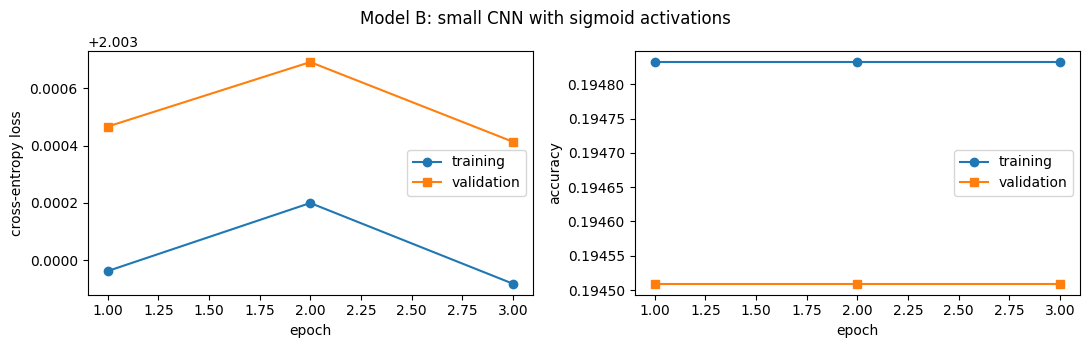

B: small CNN, sigmoid: 689221 parameters | training 19.5%  validation 19.5%  test 19.5%


In [17]:
history_B, _ = train(model_B, 3)                    # three epochs are enough to see what happens
plot_history(history_B, "Model B: small CNN with sigmoid activations")
record("B: small CNN, sigmoid", model_B, history_B)

Nothing happens. The loss is $2.003$ in every epoch and the accuracy is $19.5\%$ on all three sets: exactly the share of the most frequent class, the neutrophils. (The vertical axis of the figure is zoomed into the fourth decimal place, with the offset `+2.003`; the curves are flat.)

A network *with* a convolutional layer is worse than the dense network. Before concluding anything about convolutions we have to find out why.

### 4.2 Diagnosis of Model B

A training that does not move is not the end of the experiment; it is a result to be understood, and two measurements explain it.

The first measurement concerns the value at which the loss is stuck. A network that ignores its input can do no better than to output, for every image, the frequencies $p_c$ of the classes in the training set. Its cross-entropy is then the entropy of that distribution,
$$H(p) = -\sum_c p_c \ln p_c, \tag{4}$$
and we compare this number with the loss of Model B.

In [18]:
p_class = counts / counts.sum()
print("entropy of the class frequencies:", -(p_class * np.log(p_class)).sum())
print("loss of Model B after training  :", history_B[-1]["train_loss"])
with torch.no_grad():
    q = model_B(Xva[:5]).softmax(dim=1).cpu().numpy()
print("\noutput probabilities of Model B for five different images:\n", q.round(3))
print("class frequencies:\n", p_class.round(3))

entropy of the class frequencies: 2.0028528878494294
loss of Model B after training  : 2.002917948988471

output probabilities of Model B for five different images:
 [[0.072 0.184 0.089 0.168 0.071 0.085 0.194 0.136]
 [0.072 0.184 0.089 0.168 0.071 0.085 0.194 0.136]
 [0.072 0.184 0.089 0.168 0.071 0.085 0.194 0.136]
 [0.072 0.184 0.089 0.168 0.071 0.085 0.194 0.136]
 [0.072 0.184 0.089 0.168 0.071 0.085 0.194 0.136]]
class frequencies:
 [0.071 0.182 0.091 0.169 0.071 0.083 0.195 0.137]


The two numbers agree ($2.0029$), and the network gives the same output for every image: it has stopped looking at the input.

The second measurement locates the place where the signal is lost. We look at the *pre-activations* $z$ of the 21 hidden nodes, the numbers that enter the sigmoid, for a fresh (untrained) copy of the network and for the trained one. The sigmoid $\sigma(z)$ is flat for $|z| > 5$: its derivative
$$\sigma'(z) = \sigma(z)\big(1-\sigma(z)\big) \tag{5}$$
is below $0.007$ there, and a gradient that has to pass through such a node is multiplied by this small number.

In [19]:
def hidden_preactivations(model, x):
    # The numbers that enter the hidden activation: output of the first dense layer (index 4 of the Sequential).
    with torch.no_grad():
        for layer in list(model)[:5]:
            x = layer(x)
    return x

def make_model_B(activation):
    return nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1), activation(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * (SIZE // 2) ** 2, 21), activation(),
        nn.Linear(21, N_CLASSES))

x_check = Xtr[:256]
for name, model in [("untrained copy", make_model_B(nn.Sigmoid).to(device)), ("Model B after training", model_B)]:
    z = hidden_preactivations(model, x_check)
    s_prime = torch.sigmoid(z) * (1 - torch.sigmoid(z))
    print(f"{name:24s}: std of z = {z.std().item():7.2f}   |z| > 5 in {100 * (z.abs() > 5).float().mean().item():5.1f}% of the cases"
          f"   mean sigmoid'(z) = {s_prime.mean().item():.5f}  (largest possible: 0.25)")

features = x_check
with torch.no_grad():
    for layer in list(model_B)[:4]:
        features = layer(features)
print(f"\ninputs of the hidden layer: {features.shape[1]} numbers per image, all positive: {(features >= 0).all().item()}, mean {features.mean().item():.2f}")

untrained copy          : std of z =    0.35   |z| > 5 in   0.0% of the cases   mean sigmoid'(z) = 0.24251  (largest possible: 0.25)


Model B after training  : std of z =   98.60   |z| > 5 in 100.0% of the cases   mean sigmoid'(z) = 0.00000  (largest possible: 0.25)



inputs of the hidden layer: 32768 numbers per image, all positive: True, mean 0.52


The untrained network is healthy: the pre-activations have a spread of $0.35$, none is beyond $\pm5$, and the mean derivative of the sigmoid is $0.243$, close to its maximum $0.25$. After training the spread is $98.6$, **all** pre-activations are beyond $\pm5$, and the derivative of the sigmoid is zero to five decimal places. Every hidden node is *saturated*.

How does this happen? The hidden layer receives $32\,768$ numbers per image, and all of them are positive, because they come out of a sigmoid (their mean is $0.52$). In its first steps the Adam optimiser changes each weight by about the learning rate, $0.001$. If the changes point the same way, one single step can move a pre-activation by up to
$$32\,768 \times 0.52 \times 0.001 \approx 17. \tag{6}$$ A few steps are enough to push every hidden node deep into the flat part of the sigmoid. From then on the gradient that passes through the hidden layer is multiplied by (almost) zero: the convolutional layer and the hidden layer stop learning. The output layer sees the same hidden values for every image, and all it can still learn are the class frequencies.

This is the **vanishing-gradient problem** in its simplest form. (Model A did not suffer from it: its hidden layer receives standardised pixels, positive and negative, whose contributions largely cancel.)

### 4.3 Model B2: the same network with ReLU

The rectified linear unit,
$$\mathrm{ReLU}(z) = \max(0, z), \tag{7}$$
has derivative $1$ for every $z > 0$: it does not saturate for large inputs. We replace the two sigmoids by ReLU and change nothing else.

epoch  1: training loss 1.041 acc 0.674 | validation loss 1.048 acc 0.672  (16 s)


epoch  2: training loss 0.801 acc 0.737 | validation loss 0.829 acc 0.727  (16 s)


epoch  3: training loss 0.713 acc 0.744 | validation loss 0.749 acc 0.739  (17 s)


epoch  4: training loss 0.639 acc 0.767 | validation loss 0.686 acc 0.751  (17 s)


epoch  5: training loss 0.620 acc 0.767 | validation loss 0.672 acc 0.752  (18 s)


epoch  6: training loss 0.577 acc 0.762 | validation loss 0.642 acc 0.746  (19 s)


epoch  7: training loss 0.545 acc 0.770 | validation loss 0.621 acc 0.746  (18 s)


epoch  8: training loss 0.422 acc 0.836 | validation loss 0.522 acc 0.801  (18 s)


epoch  9: training loss 0.418 acc 0.843 | validation loss 0.526 acc 0.811  (20 s)


epoch 10: training loss 0.356 acc 0.860 | validation loss 0.472 acc 0.820  (21 s)


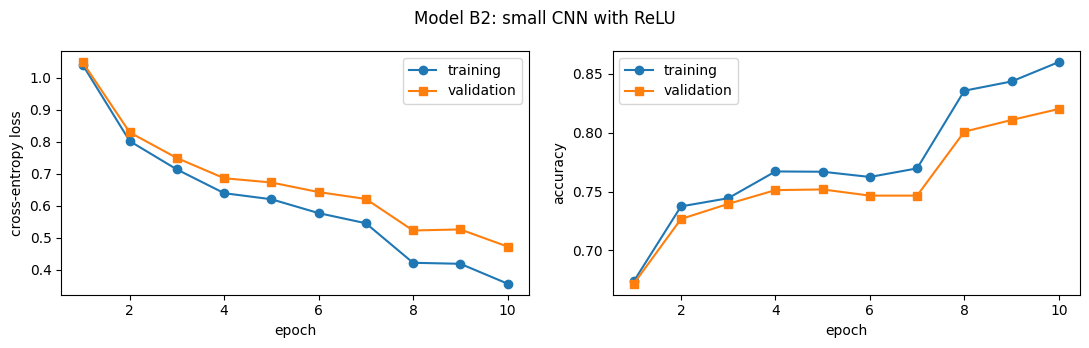

B2: small CNN, ReLU: 689221 parameters | training 86.0%  validation 82.0%  test 81.9%


In [20]:
torch.manual_seed(0)
model_B2 = make_model_B(nn.ReLU)
history_B2, _ = train(model_B2, EPOCHS_CNN)
plot_history(history_B2, "Model B2: small CNN with ReLU")
record("B2: small CNN, ReLU", model_B2, history_B2)

With ReLU the same architecture learns: $86.0\%$ training, $82.0\%$ validation, $81.9\%$ test accuracy. One convolutional layer is already six points better than the dense network ($75.6\%$); it also has more parameters ($689\,221$ against $258\,245$), almost all of them in the dense layer after `Flatten`. The training accuracy is four points above the validation accuracy.

### 4.4 Learned feature maps

The 32 kernels of the first layer have shape $3\times3\times3$ (height, width, colour). The figure shows the feature maps that the first eight kernels of Model B2 produce for one test image. Different kernels respond to different structures: edges of the cell, the nucleus, the background.

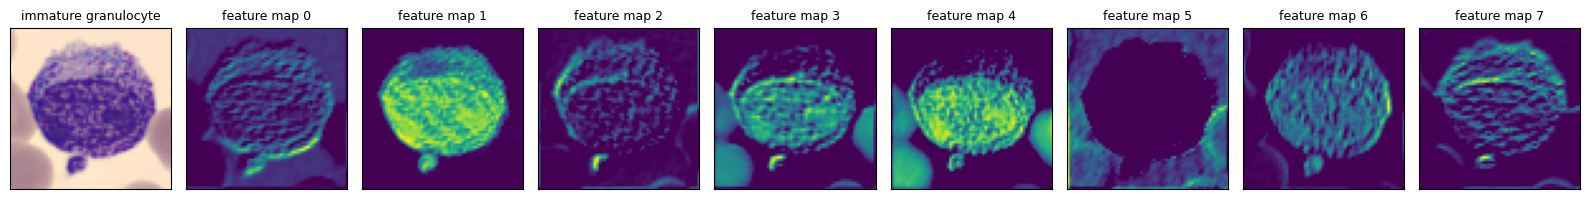

In [21]:
i = 0
with torch.no_grad():
    maps = torch.relu(model_B2[0](Xte[i:i + 1]))[0].cpu().numpy()        # (32, SIZE, SIZE)
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(X_test[i]); axes[0].set_title(class_names[y_test[i]], fontsize=9)
for k in range(8):
    axes[k + 1].imshow(maps[k], cmap="viridis"); axes[k + 1].set_title(f"feature map {k}", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

<hr/>
## 5. Model C: a larger CNN, and overfitting

More convolutional layers give a **hierarchy of features**: edges, then parts, then whole objects. Model C has three blocks of
*convolution (ReLU) + max pooling* with 32, 64 and 128 kernels, followed by a dense layer of 512 nodes.

The two loss curves diagnose it. If the training loss keeps falling while the validation loss stops falling or rises, the network **overfits**:
it memorises the training images instead of learning what the classes have in common.

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=8192, out_features=512, bias=True)
  (11): ReLU()
  (12): Linear(in_features=512, out_features=8, bias=True)
) 
parameters: 4292168


epoch  1: training loss 0.335 acc 0.886 | validation loss 0.334 acc 0.880  (36 s)


epoch  2: training loss 0.206 acc 0.925 | validation loss 0.229 acc 0.920  (34 s)


epoch  3: training loss 0.133 acc 0.955 | validation loss 0.166 acc 0.939  (41 s)


epoch  4: training loss 0.104 acc 0.965 | validation loss 0.166 acc 0.942  (38 s)


...

epoch  6: training loss 0.067 acc 0.978 | validation loss 0.153 acc 0.945  (25 s)


epoch  7: training loss 0.061 acc 0.980 | validation loss 0.159 acc 0.948  (24 s)


epoch  8: training loss 0.026 acc 0.991 | validation loss 0.137 acc 0.957  (27 s)


epoch  9: training loss 0.028 acc 0.991 | validation loss 0.147 acc 0.958  (25 s)


epoch 10: training loss 0.024 acc 0.992 | validation loss 0.162 acc 0.955  (24 s)


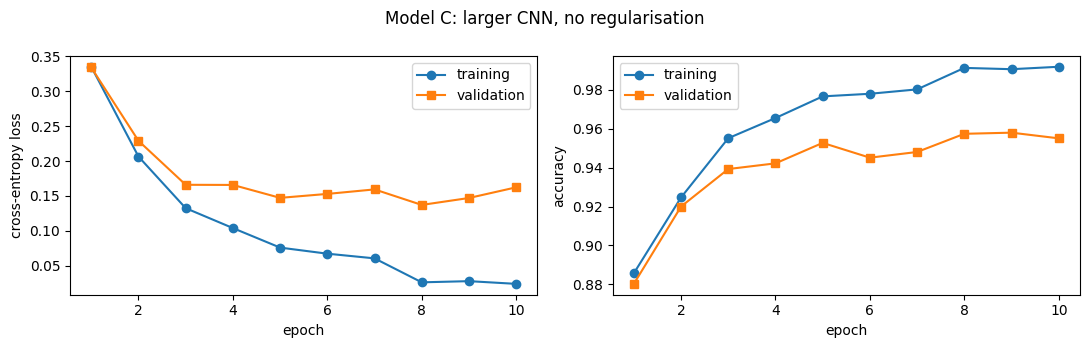

C: larger CNN: 4292168 parameters | training 99.2%  validation 95.5%  test 95.6%
gap between training and validation accuracy: 3.7 percentage points


In [22]:
def make_model_C():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(128 * (SIZE // 8) ** 2, 512), nn.ReLU(),
        nn.Linear(512, N_CLASSES))

model_C = make_model_C()
print(model_C, "\nparameters:", count_parameters(model_C))
history_C, best_state_C = train(model_C, EPOCHS_CNN)
plot_history(history_C, "Model C: larger CNN, no regularisation")
record("C: larger CNN", model_C, history_C)
gap_C = results["C: larger CNN"]["train"] - results["C: larger CNN"]["val"]
print(f"gap between training and validation accuracy: {100 * gap_C:.1f} percentage points")

Model C reaches $99.2\%$ on the training set, $95.5\%$ on the validation set and $95.6\%$ on the test set. From epoch 5 on the validation loss no longer falls ($0.147,\ 0.153,\ 0.159,\ 0.137,\ 0.147,\ 0.162$) while the training loss keeps falling from $0.076$ to $0.024$: the network is fitting details of the training images that do not help on new ones. The gap in accuracy is $3.7$ points.

The overfitting is real but mild. Single blood cells on a clean background are an easier problem than CIFAR-10, where the same experiment in the lecture gave $100\%$ against $71\%$.

<hr/>
## 6. Regularisation

**Regularisation** is any technique that constrains the training or the capacity of the model, so that the network generalises to unseen data.
We try the techniques of the lecture one at a time on Model C, and then combine them.

### 6.1 L2 penalty (weight decay)
A term is added to the loss that keeps the weights small:
$$\mathcal{L}_{\rm reg} = \mathcal{L}_{\rm original} + \lambda \sum_i \theta_i^2 . \tag{8}$$
In PyTorch the optimiser does this through the argument `weight_decay`, which plays the role of $\lambda$ (the gradient of the penalty, $2\lambda\theta_i$ up to the convention for the factor 2, is added to each gradient).

epoch  1: training loss 0.350 acc 0.876 | validation loss 0.365 acc 0.872  (25 s)


epoch  2: training loss 0.272 acc 0.898 | validation loss 0.286 acc 0.890  (26 s)


epoch  3: training loss 0.191 acc 0.932 | validation loss 0.241 acc 0.919  (33 s)


epoch  4: training loss 0.109 acc 0.966 | validation loss 0.151 acc 0.950  (31 s)


epoch  5: training loss 0.118 acc 0.959 | validation loss 0.146 acc 0.948  (26 s)


epoch  6: training loss 0.092 acc 0.970 | validation loss 0.150 acc 0.952  (34 s)


epoch  7: training loss 0.080 acc 0.976 | validation loss 0.135 acc 0.953  (25 s)


epoch  8: training loss 0.095 acc 0.963 | validation loss 0.164 acc 0.943  (25 s)


epoch  9: training loss 0.163 acc 0.940 | validation loss 0.190 acc 0.930  (26 s)


epoch 10: training loss 0.066 acc 0.978 | validation loss 0.146 acc 0.950  (29 s)


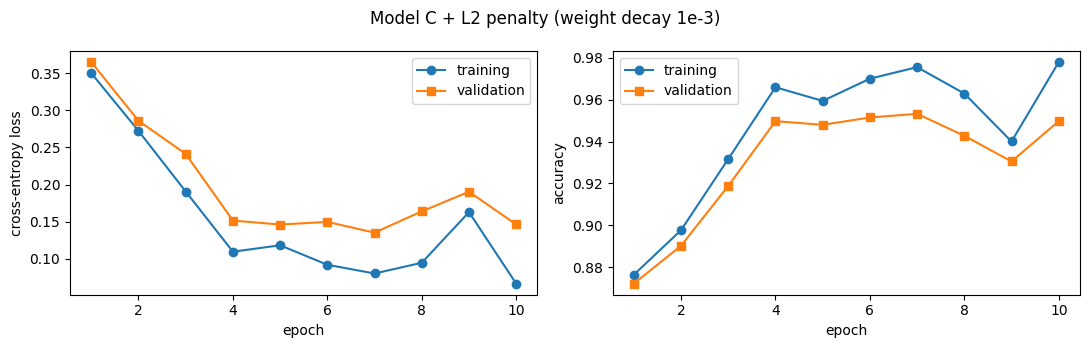

C + L2: 4292168 parameters | training 97.8%  validation 95.0%  test 95.6%


In [23]:
model_C_l2 = make_model_C()
history_C_l2, _ = train(model_C_l2, EPOCHS_CNN, weight_decay=1e-3)
plot_history(history_C_l2, "Model C + L2 penalty (weight decay 1e-3)")
record("C + L2", model_C_l2, history_C_l2)

With the L2 penalty ($\lambda = 10^{-3}$) the network reaches $97.8\%$ training, $95.0\%$ validation and $95.6\%$ test accuracy. The training accuracy is lower than without the penalty ($99.2\%$) and the final validation loss is lower ($0.146$ against $0.162$): the penalty slows down the memorising. The test accuracy is the same, $95.6\%$: on its own, and for this short training, the penalty does not buy accuracy.

### 6.2 Dropout
During training each neuron of a layer is switched off with probability $p$ (the *dropout rate*), independently for every mini-batch. The network cannot
rely on any single neuron. At test time all neurons are active; PyTorch rescales the activations by $1/(1-p)$ *during training*, so that nothing has to change at test time.

This is why the training loop calls `model.train()` and the evaluation calls `model.eval()`.

In [24]:
drop = nn.Dropout(p=0.5)
x = torch.ones(10)
drop.train(); print("training mode:", drop(x))      # about half of the entries are 0, the others are 1/(1-p) = 2
drop.eval();  print("evaluation mode:", drop(x))    # unchanged

training mode: tensor([0., 2., 2., 0., 2., 0., 2., 0., 0., 2.])
evaluation mode: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


### 6.3 Batch normalisation

A batch-normalisation layer standardises its input over the mini-batch and then rescales it with two trainable parameters $\gamma$, $\beta$:
$$\mu_B = \frac{1}{N_B}\sum_j x_j,\qquad \sigma_B^2 = \frac{1}{N_B}\sum_j (x_j-\mu_B)^2,\qquad
x_j \leftarrow \gamma\,\frac{x_j-\mu_B}{\sqrt{\sigma_B^2+\epsilon}} + \beta . \tag{9}$$
For feature maps (`nn.BatchNorm2d`) the mean and variance are computed per channel, over the mini-batch and over all positions. We check this on a random mini-batch whose four channels have mean about $5$ and standard deviation about $3$: after the layer (with the initial $\gamma = 1$, $\beta = 0$) every channel has mean $0$ and standard deviation $1$.

In [25]:
bn = nn.BatchNorm2d(4)                      # 4 channels; gamma = 1 and beta = 0 initially
x = torch.randn(16, 4, 8, 8) * 3 + 5        # a mini-batch with mean about 5 and standard deviation about 3
bn.train(); y = bn(x)
print("input : mean per channel", x.mean(dim=(0, 2, 3)).numpy().round(2), " std", x.std(dim=(0, 2, 3)).numpy().round(2))
print("output: mean per channel", y.mean(dim=(0, 2, 3)).detach().numpy().round(2), " std", y.std(dim=(0, 2, 3)).detach().numpy().round(2))

input : mean per channel [4.95 5.09 4.99 4.84]  std [2.98 3.05 3.03 2.93]
output: mean per channel [ 0. -0. -0. -0.]  std [1. 1. 1. 1.]


### 6.4 Data augmentation
New training images are produced from the existing ones by transformations that **do not change the class**. Which transformations are allowed
depends on the data. A blood smear has no preferred orientation: a cell flipped left–right or up–down is still a valid image of the same cell type.
(For hand-written digits this would be wrong: a flipped 2 is not a 2.) We use random flips in both directions and random shifts by a few pixels.

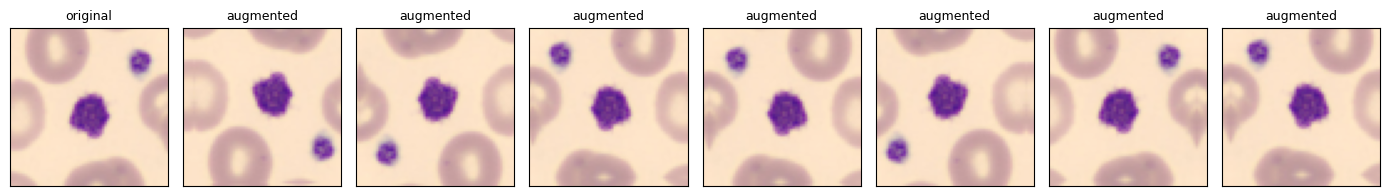

In [26]:
SHIFT = max(1, SIZE // 16)                                   # maximal shift in pixels

def augment(x):
    # Random flips (left-right, up-down) and one random shift for the mini-batch.
    x = x.clone()
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    x[flip] = x[flip].flip(3)                                # left-right
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    x[flip] = x[flip].flip(2)                                # up-down
    x = F.pad(x, (SHIFT, SHIFT, SHIFT, SHIFT), mode="reflect")
    i, j = np.random.randint(0, 2 * SHIFT + 1, size=2)
    return x[:, :, i:i + SIZE, j:j + SIZE]

def to_image(x):
    # Undo the standardisation: tensor (3, SIZE, SIZE) -> array (SIZE, SIZE, 3) with values 0..1, for plotting.
    a = x.detach().cpu().numpy().transpose(1, 2, 0) * std + mean
    return np.clip(a, 0, 1)

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
axes[0].imshow(X_train[0]); axes[0].set_title("original", fontsize=9)
for k in range(1, 8):
    axes[k].imshow(to_image(augment(Xtr[0:1])[0])); axes[k].set_title("augmented", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

### 6.5 Model D: a regularised CNN

Model D combines the techniques of this section. It has the same three convolutional blocks as Model C, now with a batch-normalisation layer after every convolution and dropout before the dense layers; it is trained with the L2 penalty ($\lambda = 10^{-4}$) and with the augmentation defined above.

parameters: 4292616


epoch  1: training loss 0.460 acc 0.851 | validation loss 0.440 acc 0.858  (44 s)


epoch  2: training loss 0.427 acc 0.850 | validation loss 0.390 acc 0.867  (39 s)


epoch  3: training loss 0.255 acc 0.905 | validation loss 0.237 acc 0.915  (39 s)


epoch  4: training loss 0.732 acc 0.750 | validation loss 0.677 acc 0.769  (43 s)


...

epoch  6: training loss 0.177 acc 0.933 | validation loss 0.155 acc 0.949  (41 s)


epoch  7: training loss 0.136 acc 0.951 | validation loss 0.143 acc 0.942  (40 s)


epoch  8: training loss 0.212 acc 0.922 | validation loss 0.210 acc 0.935  (41 s)


epoch  9: training loss 0.169 acc 0.941 | validation loss 0.166 acc 0.942  (39 s)


epoch 10: training loss 0.105 acc 0.962 | validation loss 0.108 acc 0.964  (39 s)


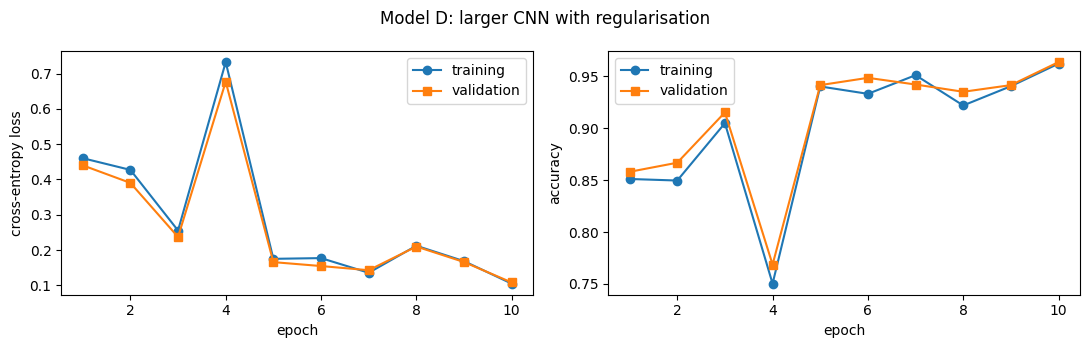

D: larger CNN + regularisation: 4292616 parameters | training 96.2%  validation 96.4%  test 96.0%
gap between training and validation accuracy: -0.1 percentage points (Model C: 3.7)


In [27]:
model_D = nn.Sequential(
    nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.2),
    nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.2),
    nn.Flatten(), nn.Dropout(0.5),
    nn.Linear(128 * (SIZE // 8) ** 2, 512), nn.ReLU(),
    nn.Linear(512, N_CLASSES))
print("parameters:", count_parameters(model_D))

history_D, best_state_D = train(model_D, EPOCHS_CNN, weight_decay=1e-4, augment=augment)
plot_history(history_D, "Model D: larger CNN with regularisation")
record("D: larger CNN + regularisation", model_D, history_D)
gap_D = results["D: larger CNN + regularisation"]["train"] - results["D: larger CNN + regularisation"]["val"]
print(f"gap between training and validation accuracy: {100 * gap_D:.1f} percentage points (Model C: {100 * gap_C:.1f})")

Model D reaches $96.2\%$ training, $96.4\%$ validation and $96.0\%$ test accuracy. The gap between training and validation is $-0.1$ points (Model C: $3.7$): the two curves lie on top of each other.

The training accuracy is *lower* than for Model C. This is expected, since dropout and augmentation make the training task harder, and the accuracies printed here are computed in evaluation mode. The test accuracy improved from $95.6\%$ to $96.0\%$, a small difference whose significance is discussed in Section 8. The curve is not smooth either: in epoch 4 the accuracy fell to $75\%$ and recovered in the next epoch. A single epoch can go wrong, one more reason to keep the parameters of the best epoch.

### 6.6 Early stopping
The training function has kept, for every model, the parameters of the epoch with the **lowest validation loss**. Early stopping means: use those
parameters instead of the last ones. For the unregularised Model C:

In [28]:
best_epoch = int(np.argmin([h["val_loss"] for h in history_C])) + 1
print(f"Model C: lowest validation loss in epoch {best_epoch} of {len(history_C)}")
model_C_early = make_model_C().to(device)
model_C_early.load_state_dict(best_state_C)
record("C + early stopping", model_C_early, history_C)

Model C: lowest validation loss in epoch 8 of 10


C + early stopping: 4292168 parameters | training 99.1%  validation 95.7%  test 96.0%


The lowest validation loss of Model C was in epoch 8. With the parameters of that epoch the network reaches $99.1\%$ training, $95.7\%$ validation and $96.0\%$ test accuracy, against $99.2\%$, $95.5\%$, $95.6\%$ for the last epoch. The gain is small here because Model C overfits only mildly, but early stopping costs nothing: the validation loss is computed anyway.

<hr/>
## 7. Model E: global average pooling and class activation maps

### 7.1 A CNN that ends with global average pooling (GAP)
Models B–D flatten the last feature maps: every weight of the dense layer belongs to one *position* of one map.
**Global average pooling** replaces each of the $K$ last feature maps $f_k(x,y)$ by a single number, its average
$$F_k = \frac{1}{hw}\sum_{x,y} f_k(x,y), \tag{10}$$
and one dense layer turns the $K$ numbers into class scores:
$$S_c = \sum_k w^c_k F_k + b_c . \tag{11}$$
Now every weight $w^c_k$ belongs to one *feature*, wherever it is in the image.

Besides the scores, the network gives access to its last feature maps (`feature_maps`), which the class activation maps of Section 7.3 need.

parameters: 288936


epoch  1: training loss 0.470 acc 0.842 | validation loss 0.422 acc 0.855  (81 s)


epoch  2: training loss 0.225 acc 0.936 | validation loss 0.208 acc 0.938  (82 s)


epoch  3: training loss 0.456 acc 0.851 | validation loss 0.437 acc 0.856  (77 s)


epoch  4: training loss 0.177 acc 0.942 | validation loss 0.169 acc 0.945  (78 s)


...

epoch  6: training loss 0.176 acc 0.939 | validation loss 0.142 acc 0.949  (79 s)


epoch  7: training loss 0.237 acc 0.921 | validation loss 0.218 acc 0.927  (79 s)


epoch  8: training loss 0.065 acc 0.977 | validation loss 0.069 acc 0.980  (79 s)


epoch  9: training loss 0.188 acc 0.940 | validation loss 0.181 acc 0.944  (80 s)


epoch 10: training loss 0.199 acc 0.935 | validation loss 0.193 acc 0.940  (80 s)


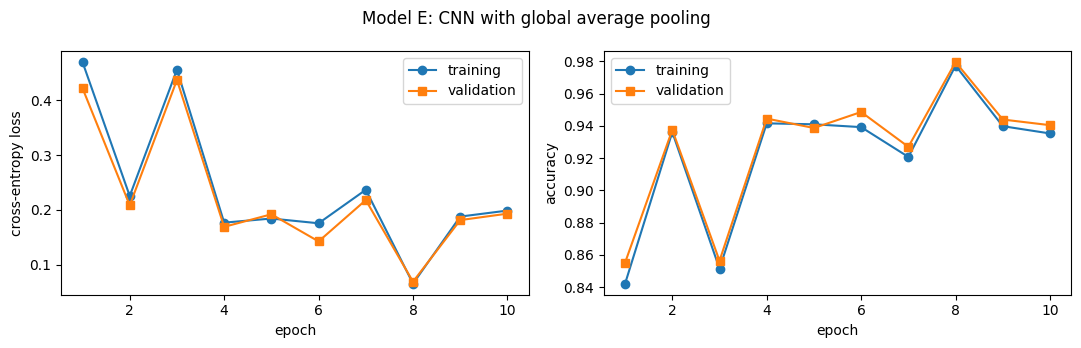

E: GAP CNN (+ batch norm, augmentation): 288936 parameters | training 93.5%  validation 94.0%  test 93.2%


In [29]:
def conv_block(n_in, n_out):
    return nn.Sequential(nn.Conv2d(n_in, n_out, 3, padding=1), nn.BatchNorm2d(n_out), nn.ReLU(),
                         nn.Conv2d(n_out, n_out, 3, padding=1), nn.BatchNorm2d(n_out), nn.ReLU())

class GapCNN(nn.Module):
    def __init__(self, n_channels=3, n_classes=N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(conv_block(n_channels, 32), nn.MaxPool2d(2),
                                      conv_block(32, 64), nn.MaxPool2d(2),
                                      conv_block(64, 128))                   # -> 128 maps (SIZE/4) x (SIZE/4)
        self.fc = nn.Linear(128, n_classes)
    def feature_maps(self, x):
        return self.features(x)
    def forward(self, x):
        f = self.features(x)
        return self.fc(f.mean(dim=(2, 3)))                                   # global average pooling, then the dense layer

model_E = GapCNN()
print("parameters:", count_parameters(model_E))
history_E, _ = train(model_E, EPOCHS_CNN, augment=augment)
plot_history(history_E, "Model E: CNN with global average pooling")
record("E: GAP CNN (+ batch norm, augmentation)", model_E, history_E)

The GAP network reaches $93.5\%$ training, $94.0\%$ validation and $93.2\%$ test accuracy with $288\,936$ parameters: fifteen times fewer than Models C and D ($4.29$ million), for two to three points less test accuracy. Almost all parameters of C and D sit in the dense layer after `Flatten`; global average pooling removes that layer. There is no gap between training and validation.

### 7.2 The confusion matrix
Entry (row $t$, column $p$) is the fraction of test images of true class $t$ that the network assigns to class $p$. The diagonal is the
accuracy per class; the off-diagonal entries show which cell types are confused with each other.

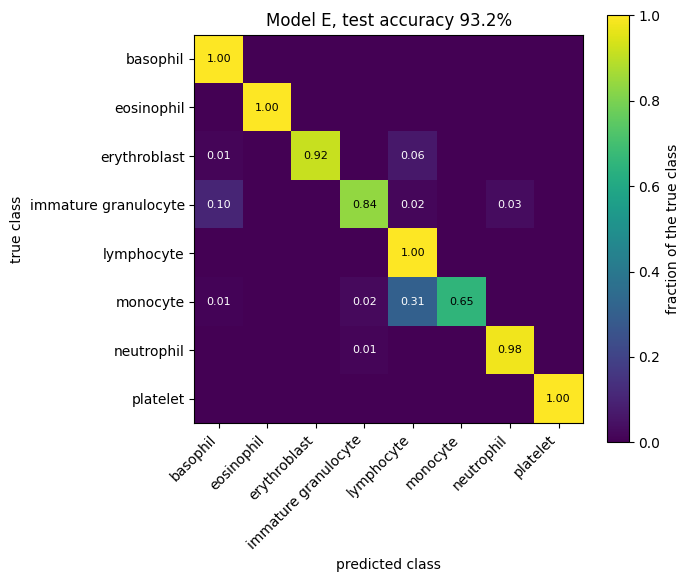

In [30]:
model_E.eval()
with torch.no_grad():
    scores_test = torch.cat([model_E(Xte[k:k + 500]) for k in range(0, len(Xte), 500)])
prob_test = scores_test.softmax(dim=1).cpu().numpy()
pred_test = prob_test.argmax(axis=1)

confusion = np.zeros((N_CLASSES, N_CLASSES))
for t, p in zip(y_test, pred_test):
    confusion[t, p] += 1
confusion_normalised = confusion / confusion.sum(axis=1, keepdims=True)

plt.figure(figsize=(7, 6))
plt.imshow(confusion_normalised, cmap="viridis", vmin=0, vmax=1); plt.colorbar(label="fraction of the true class")
plt.xticks(range(N_CLASSES), class_names, rotation=45, ha="right"); plt.yticks(range(N_CLASSES), class_names)
for t in range(N_CLASSES):
    for p in range(N_CLASSES):
        if confusion_normalised[t, p] >= 0.01:
            plt.text(p, t, f"{confusion_normalised[t, p]:.2f}", ha="center", va="center", fontsize=8,
                     color="black" if confusion_normalised[t, p] > 0.6 else "white")
plt.xlabel("predicted class"); plt.ylabel("true class"); plt.title(f"Model E, test accuracy {100 * (pred_test == y_test).mean():.1f}%")
plt.tight_layout(); plt.show()

The overall accuracy of $93.2\%$ hides large differences between the classes. Basophils, eosinophils, lymphocytes and platelets are recognised in (rounded) $100\%$ of the cases, neutrophils in $98\%$, erythroblasts in $92\%$, immature granulocytes in $84\%$ ($10\%$ of them are taken for basophils). **Monocytes are recognised in only $65\%$ of the cases: $31\%$ of them are classified as lymphocytes.** Both are white blood cells with one large nucleus.

A caution about this very result. In an earlier run of this same notebook the monocytes were recognised in $98\%$ of the cases, and the main confusion was a different one (immature granulocytes taken for neutrophils, $18\%$). After 10 epochs, *which* classes this network confuses is not stable from run to run.

### Confusion matrices of all models

We draw the same matrix for all models of this notebook, on the same test images. A single accuracy number hides *how* a model fails; the confusion matrix shows it. Each model is put in evaluation mode first (dropout off, batch normalisation uses its stored statistics). The matrices and the trained parameters are saved to disk, so that they can be used later without training again.

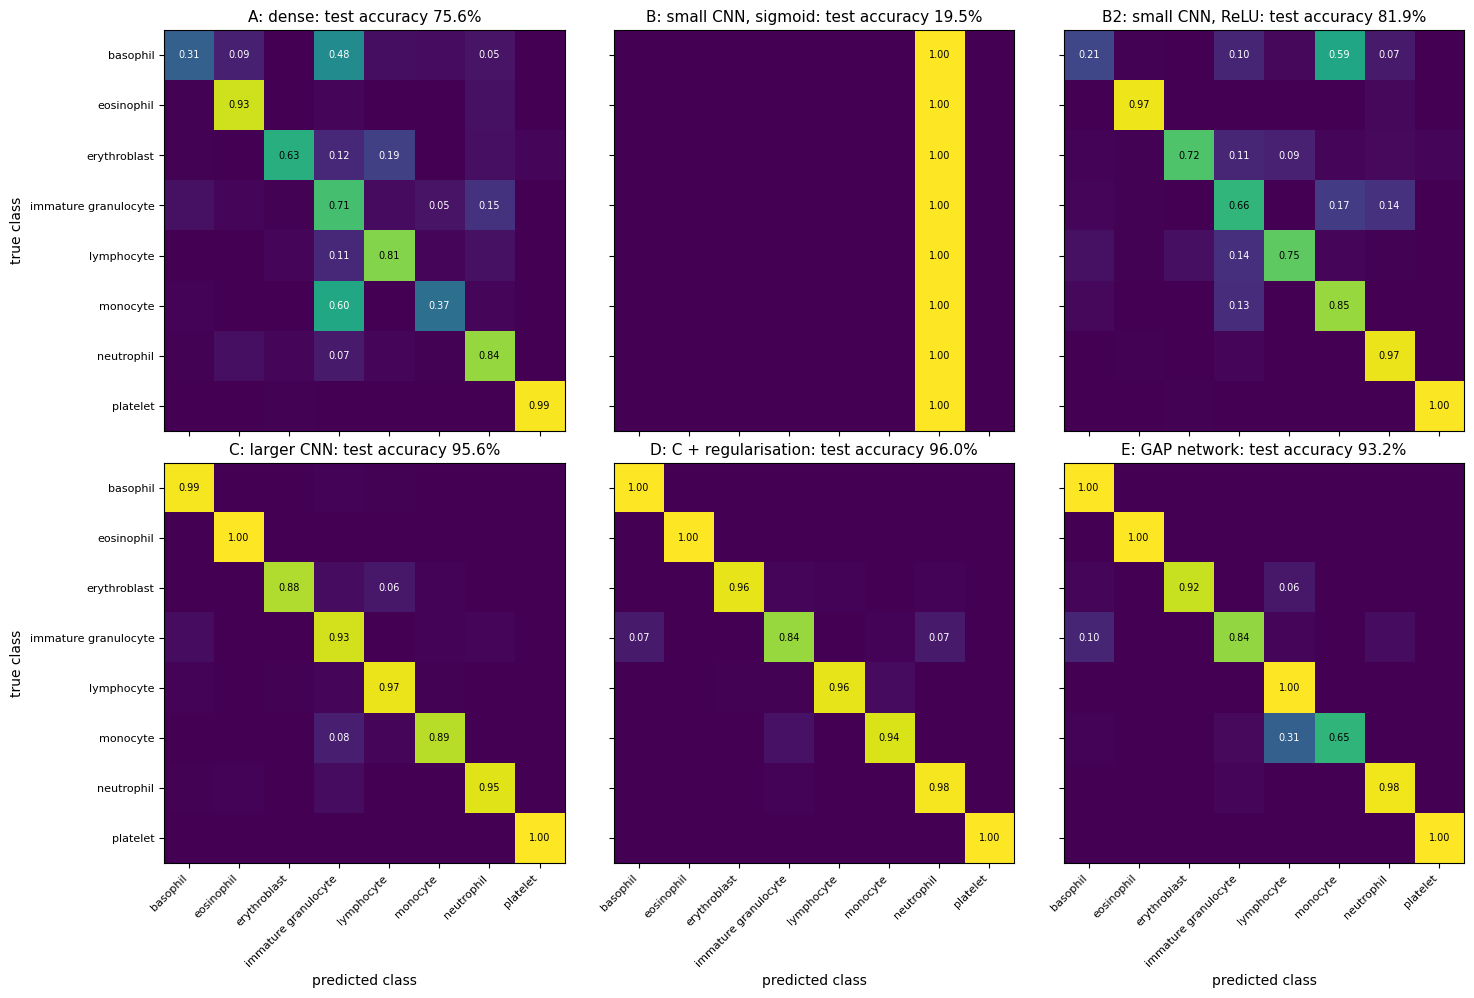

saved: results/confusion_all_models.png, results/confusion_all_models.npz, results/model_*.pt


In [31]:
def confusion_matrix_of(model):
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(Xte[k:k + 500]) for k in range(0, len(Xte), 500)]).argmax(dim=1).cpu().numpy()
    m = np.zeros((N_CLASSES, N_CLASSES))
    for t, p in zip(y_test, pred):
        m[t, p] += 1
    return m / m.sum(axis=1, keepdims=True), (pred == y_test).mean()

all_models = {"A: dense": model_A, "B: small CNN, sigmoid": model_B, "B2: small CNN, ReLU": model_B2,
              "C: larger CNN": model_C, "D: C + regularisation": model_D, "E: GAP network": model_E}
confusions = {name: confusion_matrix_of(m) for name, m in all_models.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (name, (m, acc)) in zip(axes.flat, confusions.items()):
    ax.imshow(m, cmap="viridis", vmin=0, vmax=1)
    for t in range(N_CLASSES):
        for p in range(N_CLASSES):
            if m[t, p] >= 0.05:
                ax.text(p, t, f"{m[t, p]:.2f}", ha="center", va="center", fontsize=7,
                        color="black" if m[t, p] > 0.6 else "white")
    ax.set_title(f"{name}: test accuracy {100 * acc:.1f}%", fontsize=11)
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(class_names if ax in axes[1] else [], rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(class_names if ax in axes[:, 0] else [], fontsize=8)
for ax in axes[1]: ax.set_xlabel("predicted class")
for ax in axes[:, 0]: ax.set_ylabel("true class")
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/confusion_all_models.png", dpi=150)
plt.show()

np.savez("results/confusion_all_models.npz", names=list(confusions), matrices=np.array([m for m, _ in confusions.values()]))
for name, m in all_models.items():
    torch.save(m.state_dict(), f"results/model_{name.split(':')[0]}.pt")
print("saved: results/confusion_all_models.png, results/confusion_all_models.npz, results/model_*.pt")

The six matrices tell six different stories behind the accuracies of the table. The dense Model A ($75.6\%$) recognises only platelets and eosinophils reliably; $60\%$ of its monocytes are classified as immature granulocytes, and only $31\%$ of the basophils are recognised. Model B ($19.5\%$, sigmoid) produces a single column: every image is classified as a neutrophil, the most frequent class, because the network does not look at the input. Model B2 ($81.9\%$, ReLU) has the same architecture and now learns, but $59\%$ of its basophils are taken for monocytes. Models C ($95.6\%$) and D ($96.0\%$) are almost diagonal; their largest off-diagonal entries are $8\%$ (C: monocytes taken for immature granulocytes) and $7\%$ (D: immature granulocytes taken for basophils and for neutrophils). Model E ($93.2\%$, GAP) is almost diagonal too, except one entry: $31\%$ of the monocytes are taken for lymphocytes.

Models with similar accuracy can make different mistakes; the accuracy alone does not show which cell types a model can be trusted on.

### 7.3 Class activation maps (CAM)

Insert the definition of $F_k$ into the score and **swap the two sums** (both steps are linear, so their order can be exchanged):
$$S_c = \sum_k w^c_k\,\frac{1}{hw}\sum_{x,y} f_k(x,y) + b_c \;=\; \frac{1}{hw}\sum_{x,y}\underbrace{\sum_k w^c_k\, f_k(x,y)}_{M_c(x,y)} + b_c . \tag{12}$$
The **class activation map** $M_c(x,y)$, under the brace in equation (12), is a small image, and the score of class $c$ is its average (plus the bias). Positions where $M_c$ is large are the evidence *for* class $c$.

B. Zhou et al., *Learning Deep Features for Discriminative Localization*, CVPR 2016, [arXiv:1512.04150](https://arxiv.org/abs/1512.04150).

First we check the identity numerically for one image: the average of the map plus the bias must reproduce the score of the network. For all eight classes the two agree to $5\times10^{-7}$, the rounding of 32-bit floating-point numbers.

In [32]:
def class_activation_maps(model, x):
    # Return the maps M_c(x, y) for all classes: array (N_CLASSES, h, w), for one image tensor x of shape (1, 3, SIZE, SIZE).
    model.eval()
    with torch.no_grad():
        f = model.feature_maps(x)[0]                                   # (K, h, w)
        return torch.einsum("ck,kxy->cxy", model.fc.weight, f)         # sum over k of w[c, k] * f[k, x, y]

i = 0
maps = class_activation_maps(model_E, Xte[i:i + 1])
with torch.no_grad():
    scores = model_E(Xte[i:i + 1])[0]
from_maps = (maps.mean(dim=(1, 2)) + model_E.fc.bias).detach()
print("scores of the network        :", scores.cpu().numpy().round(3))
print("average of the maps + bias   :", from_maps.cpu().numpy().round(3))
print("largest difference:", (scores - from_maps).abs().max().item())

scores of the network        : [  3.071  -4.751  -6.671   4.91   -5.793  -4.017  -4.094 -10.809]
average of the maps + bias   : [  3.071  -4.751  -6.671   4.91   -5.793  -4.017  -4.094 -10.809]
largest difference: 4.76837158203125e-07


The maps have the size of the last feature maps (`SIZE/4`). To lay a map over the image it is enlarged by bilinear interpolation;
negative values (evidence *against* the class) are set to zero and the map is scaled to its maximum.

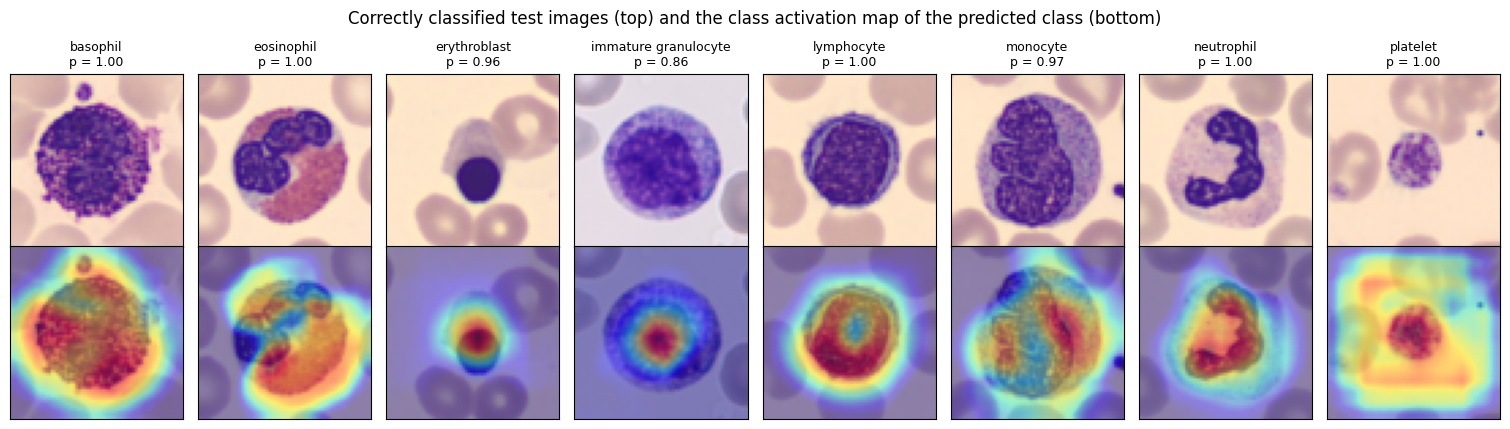

In [33]:
def draw_cam(ax, image, one_map):
    # Draw an image (array for imshow) with one class activation map (tensor h x w) on top.
    m = F.interpolate(one_map[None, None], size=image.shape[:2], mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    m = np.clip(m, 0, None)
    m = m / (m.max() + 1e-9)
    ax.imshow(image, cmap="gray"); ax.imshow(m, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])

def cam_overlay(ax, i, c, maps=None):
    # Draw blood-cell test image i with the class activation map of class c (Model E) on top.
    if maps is None:
        maps = class_activation_maps(model_E, Xte[i:i + 1])
    draw_cam(ax, X_test[i], maps[c])

rng = np.random.default_rng(1)
correct = []                                               # one correctly classified test image per class
for c in range(N_CLASSES):
    candidates = np.flatnonzero((y_test == c) & (pred_test == c))
    if len(candidates) > 0:
        correct.append(rng.choice(candidates))
fig, axes = plt.subplots(2, len(correct), figsize=(1.9 * len(correct), 4.4), squeeze=False)
for k, i in enumerate(correct):
    axes[0, k].imshow(X_test[i]); axes[0, k].set_xticks([]); axes[0, k].set_yticks([])
    axes[0, k].set_title(f"{class_names[y_test[i]]}\np = {prob_test[i, pred_test[i]]:.2f}", fontsize=9)
    cam_overlay(axes[1, k], i, pred_test[i])
fig.suptitle("Correctly classified test images (top) and the class activation map of the predicted class (bottom)")
fig.tight_layout(); plt.show()

### 7.4 One image, several classes
A class activation map exists for **every** class, not only for the predicted one. For one image we draw the maps of the three classes with the
highest probability, each scaled to its own maximum. They show which region speaks for which class.

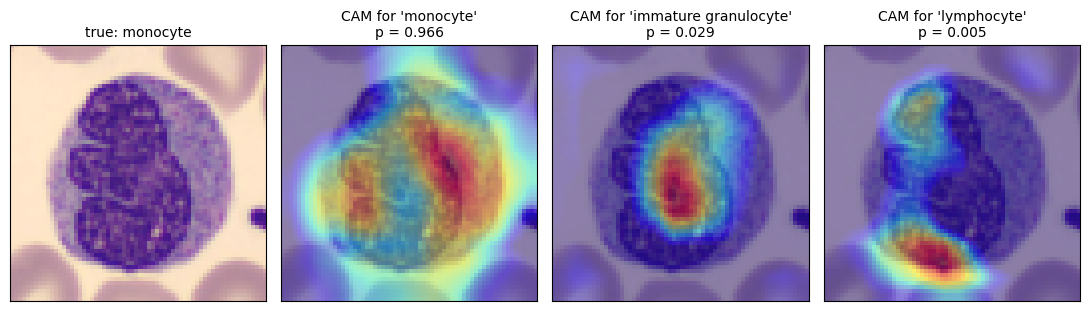

In [34]:
i = next((j for j in correct if y_test[j] == 5), correct[0])   # a monocyte, if one is in the list
maps = class_activation_maps(model_E, Xte[i:i + 1])
top3 = np.argsort(prob_test[i])[::-1][:3]
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
axes[0].imshow(X_test[i]); axes[0].set_title(f"true: {class_names[y_test[i]]}", fontsize=10)
axes[0].set_xticks([]); axes[0].set_yticks([])
for k, c in enumerate(top3):
    cam_overlay(axes[k + 1], i, c, maps)
    axes[k + 1].set_title(f"CAM for '{class_names[c]}'\np = {prob_test[i, c]:.3f}", fontsize=10)
fig.tight_layout(); plt.show()

### 7.5 Misclassified images
The most instructive images are the ones the network gets wrong. For eight misclassified test images: the true class, the predicted class with its
probability, and the map of the *predicted* class.

233 of 3421 test images are misclassified


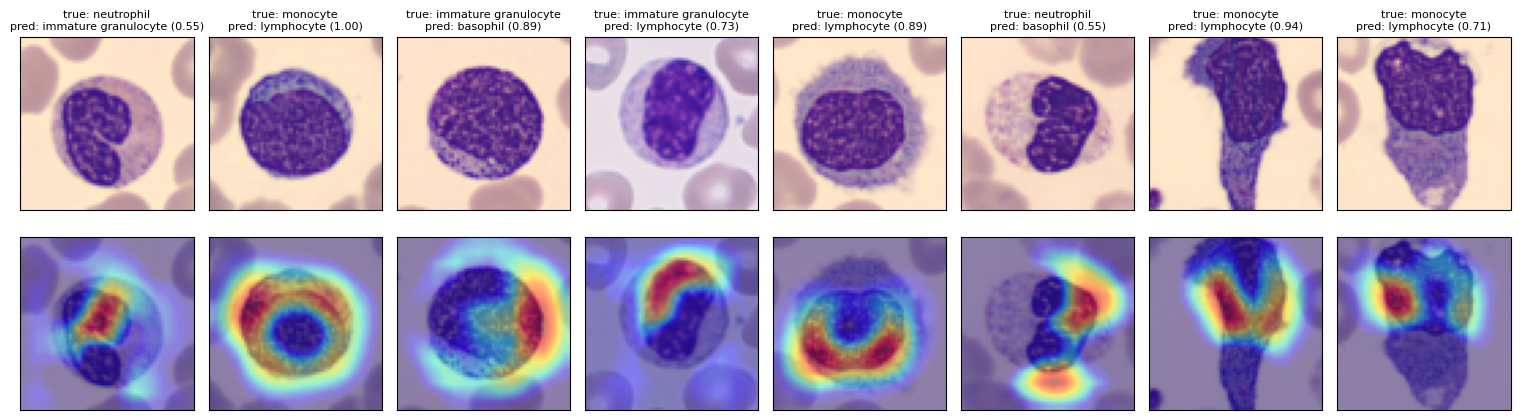

In [35]:
wrong = np.flatnonzero(pred_test != y_test)
print(f"{len(wrong)} of {len(y_test)} test images are misclassified")
chosen = rng.choice(wrong, size=min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, len(chosen), figsize=(1.9 * len(chosen), 4.6), squeeze=False)
for k, i in enumerate(chosen):
    axes[0, k].imshow(X_test[i]); axes[0, k].set_xticks([]); axes[0, k].set_yticks([])
    axes[0, k].set_title(f"true: {class_names[y_test[i]]}\npred: {class_names[pred_test[i]]} ({prob_test[i, pred_test[i]]:.2f})", fontsize=8)
    cam_overlay(axes[1, k], i, pred_test[i])
fig.tight_layout(); plt.show()

In the correctly classified examples the maps lie on the cell, not on the red blood cells around it. For the platelet, a very small object, the map covers a large part of the image. For the monocyte of Section 7.4 the three maps point to different parts of the cell: the evidence for "monocyte" ($p = 0.966$) is spread over the nucleus, that for "immature granulocyte" ($0.029$) and "lymphocyte" ($0.005$) sits in smaller regions.

Of the $3\,421$ test images $233$ are misclassified. Several of the eight shown here are monocytes classified as lymphocytes, some with a probability close to $1$: wrong and confident.

A class activation map shows *where* in the image the evidence for a class is located, at the resolution of the last feature maps. It does not show *what* the network recognised there, and a map that covers the cell is not a proof that the network uses the same criteria as a pathologist. A map that lights up on the background, however, is a clear warning.

<hr/>
## 8. Comparison of all models

The table is computed from the models trained above.

In [36]:
print(f"{'model':42s} {'parameters':>11s} {'training':>9s} {'validation':>11s} {'test':>7s}")
for name, r in results.items():
    print(f"{name:42s} {r['parameters']:11d} {100 * r['train']:8.1f}% {100 * r['val']:10.1f}% {100 * r['test']:6.1f}%")

model                                       parameters  training  validation    test
A: dense network                                258245     78.3%       75.2%   75.6%
B: small CNN, sigmoid                           689221     19.5%       19.5%   19.5%
B2: small CNN, ReLU                             689221     86.0%       82.0%   81.9%
C: larger CNN                                  4292168     99.2%       95.5%   95.6%
C + L2                                         4292168     97.8%       95.0%   95.6%
D: larger CNN + regularisation                 4292616     96.2%       96.4%   96.0%
C + early stopping                             4292168     99.1%       95.7%   96.0%
E: GAP CNN (+ batch norm, augmentation)         288936     93.5%       94.0%   93.2%


Read from top to bottom, the table retraces the notebook. The dense network reaches $75.6\%$; the small CNN with sigmoid does not learn ($19.5\%$); the same network with ReLU reaches $81.9\%$; the larger CNN reaches $95.6\%$, with a gap of $3.7$ points between training and validation; with regularisation it reaches $96.0\%$ and the gap closes; and the GAP network reaches $93.2\%$ with fifteen times fewer parameters.

The differences between "C", "C + L2", "C + early stopping" and "D" on the test set are about half a point. This is **less than the variation between two runs of the same code**: in an earlier run of this notebook Model E reached $94.0\%$ instead of $93.2\%$, and Model C $94.7\%$ instead of $95.6\%$. From one run we can say that regularisation closes the gap between training and validation; we cannot say that one of these models is more accurate than the other. For that one needs several runs with different random seeds and a mean with a standard deviation (Exercise 10).

### Model architectures

The table compares the models by their numbers; the diagrams and summaries below compare their structure, with a drawing function of our own and with two libraries that read the architecture directly from a PyTorch model.

The function `draw_network` draws a fully connected network as it is usually sketched on a blackboard. Each layer is a column of circles, one per neuron, and thin grey lines join every neuron to every neuron of the next layer, since a dense layer connects all of them. A layer with more than `max_nodes` neurons is shown by its first and last few neurons with a vertical ellipsis in between, and its true size is written under the column. The height of a column grows with the logarithm of the layer size, so a wide layer is visibly taller than a narrow one. Input and output layers are grey and hidden layers blue; orange is reserved for a latent layer and green for an additional input such as a class label.

For a network of your own, pass the layer sizes from the input to the output, e.g. `draw_network([784, 128, 10])`; `labels`, `colors` and `groups` (brackets over ranges of columns) are optional, and `ax=` draws into a panel of an existing figure. An entry of the list may itself be a list of sizes: the column then holds several blocks, which is how two inputs entering the same layer are drawn. Only dense layers can be drawn this way. A convolutional layer is a set of small kernels shared by all positions of the image, not a column of independent neurons, so the convolutional part of a network is left to the library tools further below.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


Model A is a dense network, and the first panel is all of it: $12\,288$ inputs (three colour values for each of $64\times64$ pixels), $21$ hidden sigmoid units and $8$ outputs. The CNNs end in dense layers as well, drawn in the other panels: $32\,768$ flattened feature-map values feed $21$ hidden units in Models B and B2, $8\,192$ feed $512$ in Models C and D, and in Model E global average pooling leaves $128$ numbers connected directly to the $8$ outputs. In Models B, C and D most parameters of the table are the edges between the first two columns; in Model E this layer has $1\,032$.

Model A: layers [12288, 21, 8], 258245 of the 258245 parameters
Models B and B2, dense part: layers [32768, 21, 8], 688325 of the 689221 parameters


Models C and D, dense part: layers [8192, 512, 8], 4198920 of the 4292168 parameters
Model E, dense part: layers [128, 8], 1032 of the 288936 parameters


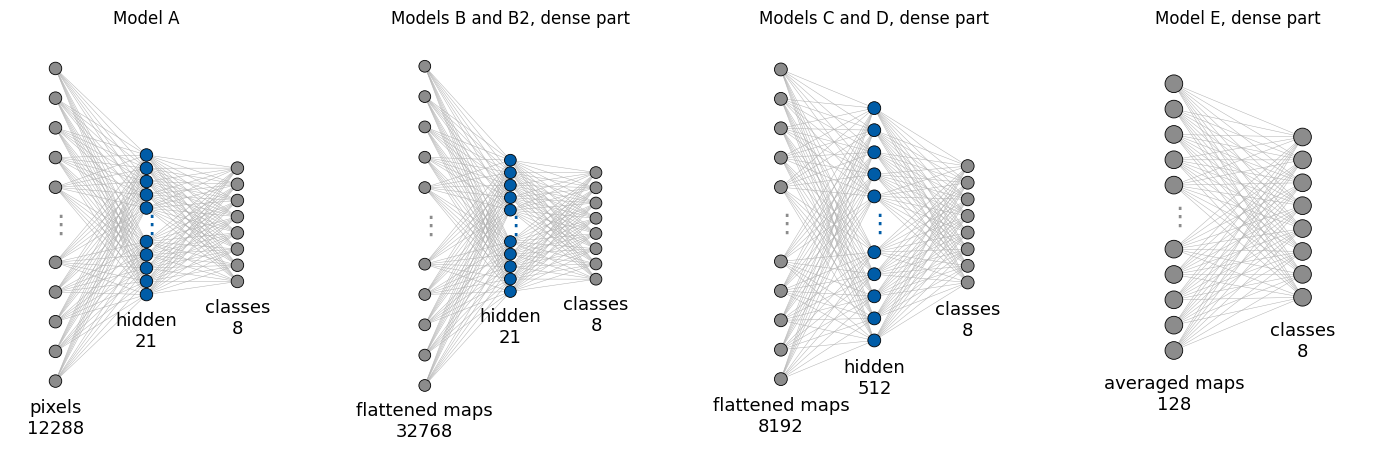

In [ ]:
def dense_layers(model):
    # the nn.Linear layers of a model, in the order of model.modules()
    return [m for m in model.modules() if isinstance(m, nn.Linear)]

heads = [("Model A", model_A, ["pixels", "hidden", "classes"]),
         ("Models B and B2, dense part", model_B2, ["flattened maps", "hidden", "classes"]),
         ("Models C and D, dense part", model_C, ["flattened maps", "hidden", "classes"]),
         ("Model E, dense part", model_E, ["averaged maps", "classes"])]
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))
for ax, (title, m, labels) in zip(axes, heads):
    layers = dense_layers(m)
    sizes = [layers[0].in_features] + [l.out_features for l in layers]    # read from the model
    draw_network(sizes, labels=labels, ax=ax)
    ax.set_title(title)
    n_drawn = sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))     # weights and biases of the drawn edges
    assert n_drawn == sum(p.numel() for l in layers for p in l.parameters())
    print(f"{title}: layers {sizes}, {n_drawn} of the {count_parameters(m)} parameters")
plt.show()


The library way to inspect a PyTorch model is `torchinfo.summary`. It sends one input through the model and prints one row per layer, with the shape of the layer's output and its number of parameters, followed by the totals, split into trainable and non-trainable parameters. The input is given by its shape, `input_size=(1, 3, SIZE, SIZE)`, or as a tensor, `input_data=...`. We pass a tensor of zeros: with `input_size` the library draws a random input, which would advance PyTorch's random number generator and change the training runs that follow. `col_names` selects the columns and `depth` the level of nested modules that is expanded; the model itself, including its training or evaluation mode, is left unchanged. Both libraries are installed with `pip install torchinfo torchview`; the first lines of the code install them when they are missing. The totals reproduce the parameter column of the table. Models C and D differ by the scales and shifts of batch normalisation,
$$2\cdot(32+64+128)=448 \tag{13}$$
parameters. In Model E the global average pooling is absent from the list: it is the operation `f.mean(dim=(2, 3))` in `forward`, not a module.

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("torchinfo") is None or importlib.util.find_spec("torchview") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchinfo", "torchview", "graphviz"])   # e.g. in Google Colab
from torchinfo import summary
from torchview import draw_graph
import IPython.display as ipd

for name, m in [("A", model_A), ("B", model_B), ("B2", model_B2), ("C", model_C), ("D", model_D), ("E", model_E)]:
    print("Model", name)
    print(summary(m, input_data=torch.zeros(1, 3, SIZE, SIZE, device=device), col_names=("output_size", "num_params"),
                  depth=2, verbose=0))


Model A
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 8]                    --
├─Flatten: 1-1                           [1, 12288]                --
├─Linear: 1-2                            [1, 21]                   258,069
├─Sigmoid: 1-3                           [1, 21]                   --
├─Linear: 1-4                            [1, 8]                    176
Total params: 258,245
Trainable params: 258,245
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.26
Input size (MB): 0.05
Forward/backward pass size (MB): 0.00
Params size (MB): 1.03
Estimated Total Size (MB): 1.08
Model B
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 8]                    --
├─Conv2d: 1-1                            [1, 32, 64, 64]           896
├─Sigmoid: 1-2                           [1, 32, 64, 64]           --
├─MaxPool2d: 1-3                        

`torchview.draw_graph` traces the same forward pass and draws it as a graph: every layer is a box with the shapes of its input and output tensors, and the arrows follow the data. With `expand_nested=True` each submodule (an `nn.Sequential` inside the model, for example) becomes a frame around its own layers. The result is a Graphviz object; `graph.visual_graph.render` writes it to a PNG file, which needs the Graphviz program `dot` (preinstalled in Google Colab). The table is the tool for checking shapes and counting parameters, for instance after a layer has been resized; the graph shows the flow of data, which matters once a model has nested blocks, branches or skip connections. In Model E the three convolutional blocks are submodules, so each appears as a frame holding its two convolutions, batch normalisations and activations.

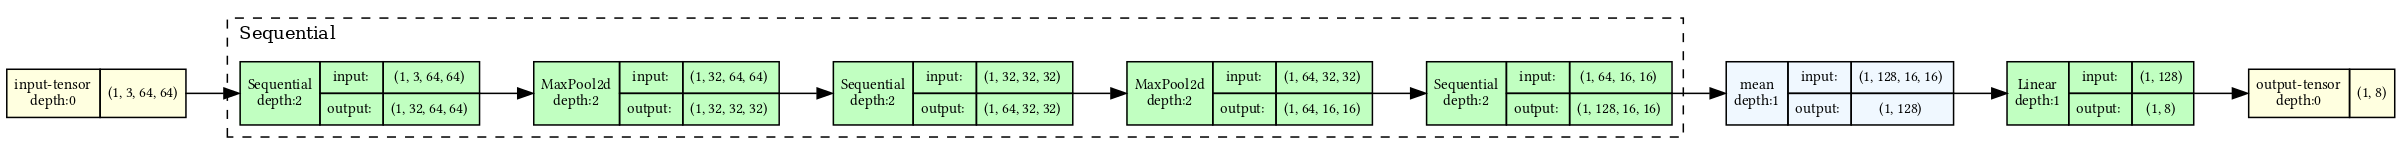

In [ ]:
os.makedirs("figures", exist_ok=True)
graph = draw_graph(model_E, input_data=torch.zeros(1, 3, SIZE, SIZE, device=device), expand_nested=True, depth=2, graph_dir="LR", device=device)
graph.visual_graph.graph_attr.update(dpi="200")                  # left to right, wide enough for a 16:9 slide
graph.visual_graph.render("figures/BloodMNIST_model_E_graph", format="png", cleanup=True)
ipd.display(ipd.Image(filename="figures/BloodMNIST_model_E_graph.png"))


<hr/>
## 9. Satellite images (EuroSAT)

The recipe does not depend on blood cells. We apply the same GAP network, the same training loop and the same class activation maps to images taken from orbit.

The data set is described in P. Helber, B. Bischke, A. Dengel, D. Borth, *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, *IEEE J. Sel. Top. Appl. Earth Obs. Remote Sens.* **12**, 2217 (2019), [doi:10.1109/JSTARS.2019.2918242](https://doi.org/10.1109/JSTARS.2019.2918242), [arXiv:1709.00029](https://arxiv.org/abs/1709.00029). It contains $27\,000$ labelled, geo-referenced image patches from the **Sentinel-2** satellites of the European Earth-observation programme Copernicus. Each sample is one patch of $64\times64$ pixels; the satellite records 13 spectral bands, and we use the version with the three visible bands (red, green, blue). The label is the **land use / land cover** class of the patch, one of ten (see the table). The data set comes without a fixed split, so we draw a random one ourselves: 70% training, 10% validation, 20% test.

| label | class | what is on the ground | images |
|---|---|---|---|
| 0 | AnnualCrop | fields with crops sown and harvested every year | 3000 |
| 1 | Forest | forest | 3000 |
| 2 | HerbaceousVegetation | grass and other low natural vegetation | 3000 |
| 3 | Highway | a motorway or major road crossing the patch | 2500 |
| 4 | Industrial | industrial buildings | 2500 |
| 5 | Pasture | grazing land | 2000 |
| 6 | PermanentCrop | orchards, vineyards and similar | 2500 |
| 7 | Residential | residential buildings | 3000 |
| 8 | River | a river crossing the patch | 2500 |
| 9 | SeaLake | sea or lake | 3000 |

The task is to predict the land-use class of one satellite patch: again *supervised learning*, now a *classification into 10 classes*. Such a classifier, applied to every patch of a large area and repeated over the years, turns raw satellite images into land-use maps and into maps of land-use *change*.

Only a few things change with respect to the blood cells:

| | blood cells | satellite patches |
|---|---|---|
| input | $64\times64\times3$ | $64\times64\times3$ |
| outputs | 8 | 10 |
| split | given | drawn by us |
| augmentation | flips, shifts | flips, shifts **and rotations by 90°** |

Seen from above there is no "up": a patch rotated by 90° is an equally valid patch of the same class. The augmentation follows the data.

### 9.1 EuroSAT archive

EuroSAT is distributed as a zip archive of JPEG files, one folder per class. `zipfile` reads the archive without unpacking it to disk, and `PIL.Image.open` decodes one JPEG into an array. To keep the calculation short on a CPU we use `N_PER_CLASS = 1000` randomly chosen images per class; set it to `None` to use all $27\,000$.

In [37]:
import zipfile, io
from PIL import Image

N_PER_CLASS = 1000                      # images per class used here; None = all
path_s = os.path.join(DATA_DIR, "EuroSAT.zip")
try:
    download("https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/EuroSAT.zip", path_s, tries=2)
except RuntimeError:
    download("https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1", path_s)

archive = zipfile.ZipFile(path_s)
files = sorted(name for name in archive.namelist() if name.lower().endswith(".jpg"))
names_s = sorted({name.split("/")[-2] for name in files})          # the folder name is the class
print(len(files), "images in", len(names_s), "classes:", names_s)

rng_s = np.random.default_rng(0)
chosen_files = []
for c, name in enumerate(names_s):
    of_class = [f for f in files if f.split("/")[-2] == name]
    if N_PER_CLASS is not None:
        of_class = list(rng_s.choice(of_class, size=N_PER_CLASS, replace=False))
    chosen_files += [(f, c) for f in of_class]

S_images = np.stack([np.array(Image.open(io.BytesIO(archive.read(f))).convert("RGB")) for f, c in chosen_files])
s_labels = np.array([c for f, c in chosen_files])
print("images:", S_images.shape, S_images.dtype, "  labels:", s_labels.shape, "  images per class:", np.bincount(s_labels))

27000 images in 10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


images: (10000, 64, 64, 3) uint8   labels: (10000,)   images per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


### 9.2 Example patches

Five patches of every class. Some classes differ in *colour* (forest, sea), others mainly in *structure*: a river and a highway are both thin lines, and annual crop and permanent crop are both field patterns.

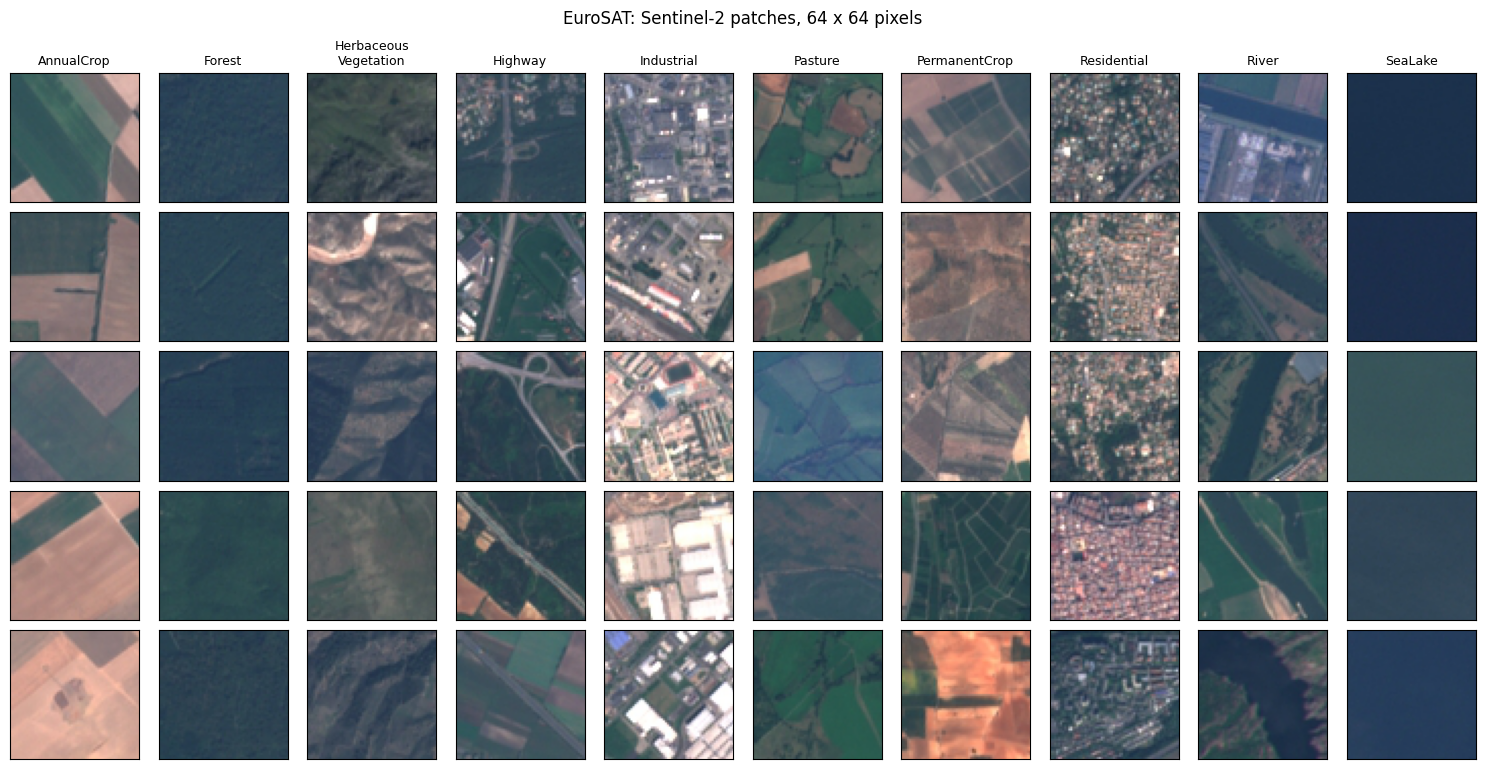

In [38]:
fig, axes = plt.subplots(5, len(names_s), figsize=(15, 7.8))
for c in range(len(names_s)):
    for row, p in enumerate(np.flatnonzero(s_labels == c)[:5]):
        axes[row, c].imshow(S_images[p]); axes[row, c].set_xticks([]); axes[row, c].set_yticks([])
    axes[0, c].set_title(names_s[c].replace("Vegetation", "\nVegetation"), fontsize=9)
fig.suptitle("EuroSAT: Sentinel-2 patches, 64 x 64 pixels"); fig.tight_layout(); plt.show()

### 9.3 Training, validation and test split

The images are put in a random order (with a fixed seed, so that the split is the same in every run) and cut into three parts. The test part is not touched until the end.

In [39]:
order = rng_s.permutation(len(S_images))
n_train, n_val = int(0.7 * len(order)), int(0.1 * len(order))
i_train, i_val, i_test = order[:n_train], order[n_train:n_train + n_val], order[n_train + n_val:]
print("training:", len(i_train), " validation:", len(i_val), " test:", len(i_test))

mean_s = S_images[i_train].reshape(-1, 3).mean(axis=0) / 255          # statistics of the training part only
std_s  = S_images[i_train].reshape(-1, 3).std(axis=0) / 255

def to_tensor_s(X):
    x = torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    m = torch.tensor(mean_s, dtype=torch.float32)[:, None, None]
    s = torch.tensor(std_s, dtype=torch.float32)[:, None, None]
    return ((x - m) / s).to(device)

Str, Sva, Ste = to_tensor_s(S_images[i_train]), to_tensor_s(S_images[i_val]), to_tensor_s(S_images[i_test])
ttr = torch.tensor(s_labels[i_train], dtype=torch.long, device=device)
tva = torch.tensor(s_labels[i_val],   dtype=torch.long, device=device)
tte = torch.tensor(s_labels[i_test],  dtype=torch.long, device=device)
S_test, t_test = S_images[i_test], s_labels[i_test]
print("always answering one class gives at most", f"{100 * np.bincount(s_labels[i_train]).max() / len(i_train):.1f}% on the training set")

training: 7000  validation: 1000  test: 2000


always answering one class gives at most 10.3% on the training set


### 9.4 Augmentation for images taken from above
Flips, shifts, and in addition a rotation by $0°$, $90°$, $180°$ or $270°$ (`torch.rot90`), the same for all images of a mini-batch.

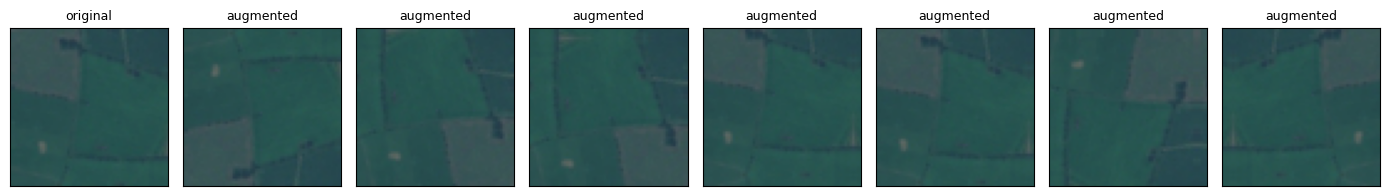

In [40]:
SHIFT_S = 4

def augment_satellite(x):
    x = x.clone()
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    x[flip] = x[flip].flip(3)
    x = torch.rot90(x, k=int(np.random.randint(0, 4)), dims=(2, 3))     # rotation by k * 90 degrees
    x = F.pad(x, (SHIFT_S, SHIFT_S, SHIFT_S, SHIFT_S), mode="reflect")
    i, j = np.random.randint(0, 2 * SHIFT_S + 1, size=2)
    return x[:, :, i:i + 64, j:j + 64]

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
axes[0].imshow(S_images[i_train[0]]); axes[0].set_title("original", fontsize=9)
for k in range(1, 8):
    a = augment_satellite(Str[0:1])[0].cpu().numpy().transpose(1, 2, 0) * std_s + mean_s
    axes[k].imshow(np.clip(a, 0, 1)); axes[k].set_title("augmented", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

### 9.5 The same network, ten outputs
`GapCNN` is the network of Section 7; only the number of outputs changes.

epoch  1: training loss 0.839 acc 0.719 | validation loss 0.807 acc 0.718  (48 s)


epoch  2: training loss 0.724 acc 0.751 | validation loss 0.723 acc 0.742  (60 s)


epoch  3: training loss 0.642 acc 0.782 | validation loss 0.633 acc 0.771  (62 s)


epoch  4: training loss 0.486 acc 0.844 | validation loss 0.509 acc 0.822  (60 s)


epoch  5: training loss 0.418 acc 0.867 | validation loss 0.429 acc 0.859  (65 s)


epoch  6: training loss 0.505 acc 0.823 | validation loss 0.565 acc 0.793  (55 s)


epoch  7: training loss 0.529 acc 0.810 | validation loss 0.553 acc 0.800  (52 s)


epoch  8: training loss 0.378 acc 0.869 | validation loss 0.414 acc 0.849  (53 s)


epoch  9: training loss 0.359 acc 0.876 | validation loss 0.378 acc 0.866  (53 s)


epoch 10: training loss 0.443 acc 0.852 | validation loss 0.485 acc 0.830  (52 s)


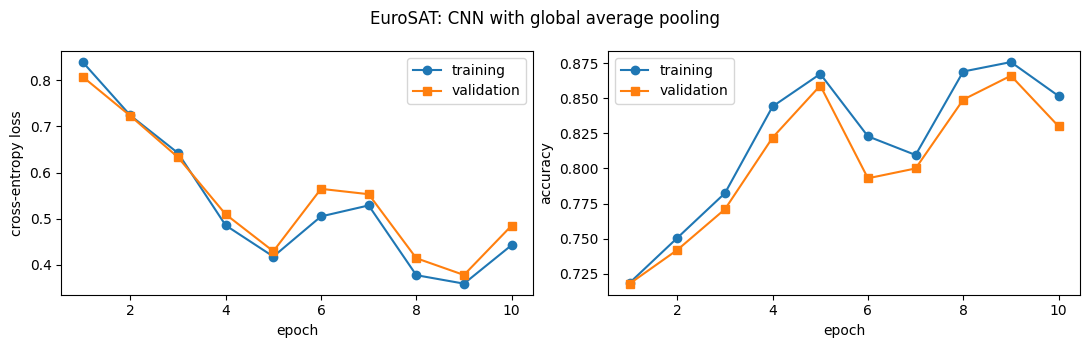

training 85.2%  validation 83.0%  test 84.4%


In [41]:
model_S = GapCNN(n_channels=3, n_classes=len(names_s))
history_S, _ = train(model_S, EPOCHS_CNN, augment=augment_satellite, data=(Str, ttr, Sva, tva))
plot_history(history_S, "EuroSAT: CNN with global average pooling")
acc_s = {name: evaluate(model_S, X, y)[0] for name, X, y in [("training", Str, ttr), ("validation", Sva, tva), ("test", Ste, tte)]}
print("  ".join(f"{k} {100 * v:.1f}%" for k, v in acc_s.items()))

### 9.6 Confusion between land-use classes

The accuracy per class and the confusion matrix on the test patches show which land-use classes the network separates well and which it mixes up.

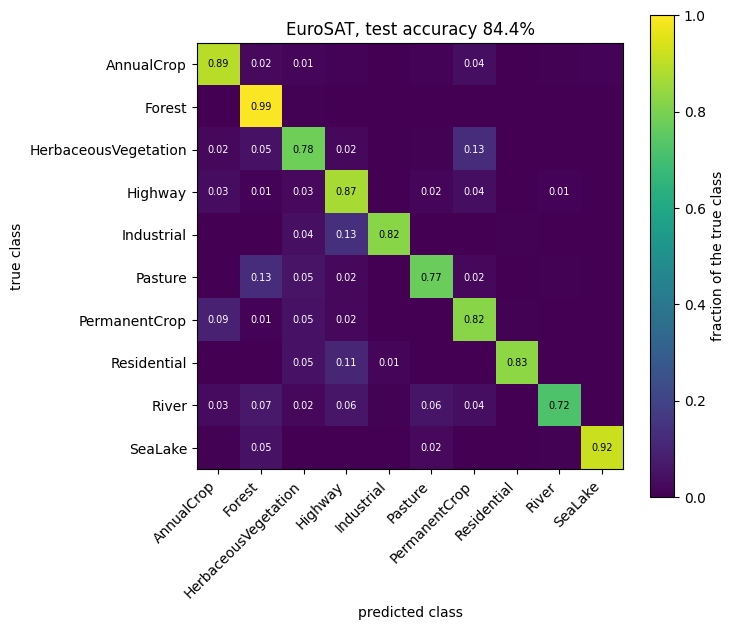

accuracy per class:
  AnnualCrop              89.2%
  Forest                  99.5%
  HerbaceousVegetation    77.9%
  Highway                 86.9%
  Industrial              82.1%
  Pasture                 77.2%
  PermanentCrop           82.3%
  Residential             83.0%
  River                   72.2%
  SeaLake                 91.9%
largest confusion: 13.3% of 'Industrial' classified as 'Highway'


In [42]:
model_S.eval()
with torch.no_grad():
    prob_s = torch.cat([model_S(Ste[k:k + 500]) for k in range(0, len(Ste), 500)]).softmax(dim=1).cpu().numpy()
pred_s = prob_s.argmax(axis=1)
confusion_s = np.zeros((len(names_s), len(names_s)))
for t, p in zip(t_test, pred_s):
    confusion_s[t, p] += 1
confusion_s_normalised = confusion_s / confusion_s.sum(axis=1, keepdims=True)

plt.figure(figsize=(7.5, 6.5))
plt.imshow(confusion_s_normalised, cmap="viridis", vmin=0, vmax=1); plt.colorbar(label="fraction of the true class")
plt.xticks(range(len(names_s)), names_s, rotation=45, ha="right"); plt.yticks(range(len(names_s)), names_s)
for t in range(len(names_s)):
    for p in range(len(names_s)):
        if confusion_s_normalised[t, p] >= 0.01:
            plt.text(p, t, f"{confusion_s_normalised[t, p]:.2f}", ha="center", va="center", fontsize=7,
                     color="black" if confusion_s_normalised[t, p] > 0.6 else "white")
plt.xlabel("predicted class"); plt.ylabel("true class"); plt.title(f"EuroSAT, test accuracy {100 * (pred_s == t_test).mean():.1f}%")
plt.tight_layout(); plt.show()

print("accuracy per class:")
for c, name in enumerate(names_s):
    print(f"  {name:22s} {100 * confusion_s_normalised[c, c]:5.1f}%")
off = confusion_s_normalised.copy(); np.fill_diagonal(off, 0)
t_max, p_max = np.unravel_index(off.argmax(), off.shape)
print(f"largest confusion: {100 * off[t_max, p_max]:.1f}% of '{names_s[t_max]}' classified as '{names_s[p_max]}'")

### 9.7 Class activation maps on satellite images

One correctly classified test patch per class and the class activation map of that class. For classes defined by an *object* (river, highway) the map should follow the object; for classes defined by a *texture* that fills the patch (forest, sea) there is no single place to point at.

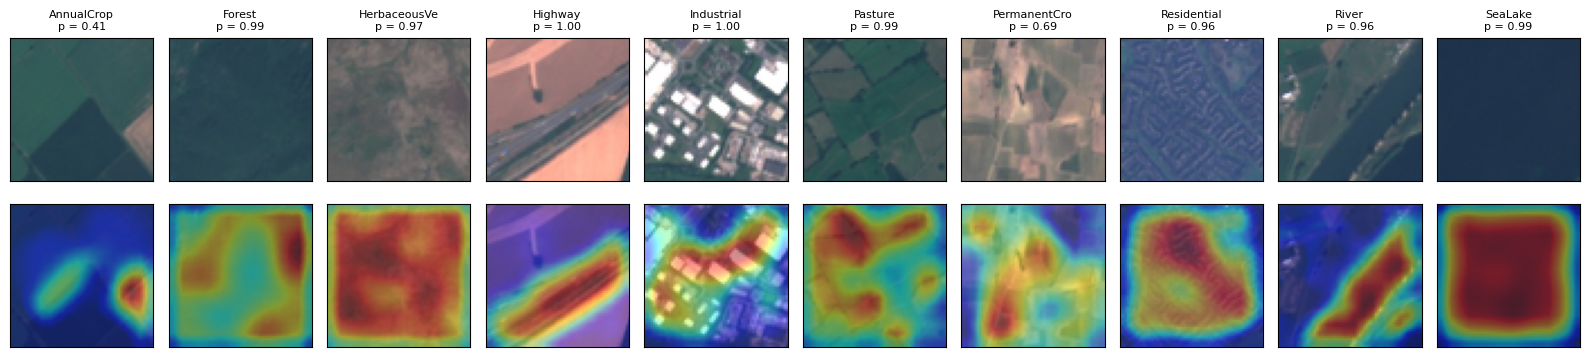

In [43]:
shown = []
for c in range(len(names_s)):
    candidates = np.flatnonzero((t_test == c) & (pred_s == c))
    if len(candidates) > 0:
        shown.append(rng_s.choice(candidates))
fig, axes = plt.subplots(2, len(shown), figsize=(1.6 * len(shown), 3.9), squeeze=False)
for k, i in enumerate(shown):
    axes[0, k].imshow(S_test[i]); axes[0, k].set_xticks([]); axes[0, k].set_yticks([])
    axes[0, k].set_title(f"{names_s[t_test[i]][:12]}\np = {prob_s[i, pred_s[i]]:.2f}", fontsize=8)
    draw_cam(axes[1, k], S_test[i], class_activation_maps(model_S, Ste[i:i + 1])[pred_s[i]])
fig.tight_layout(); plt.show()

With $1\,000$ patches per class and 10 epochs the network reaches $85.2\%$ training, $83.0\%$ validation and $84.4\%$ test accuracy; the trivial answer gives about $10\%$.

Forest is recognised in $99.5\%$ of the cases and SeaLake in $91.9\%$; River is the worst class with $72.2\%$, followed by Pasture ($77.2\%$) and HerbaceousVegetation ($77.9\%$). The largest confusions are $13\%$ of Industrial patches classified as Highway, $13\%$ of Pasture as Forest, $13\%$ of HerbaceousVegetation as PermanentCrop and $11\%$ of Residential as Highway.

The training has not converged. The validation accuracy fell from $86.6\%$ in epoch 9 to $83.0\%$ in epoch 10, and an earlier run of this same notebook ended at $90.0\%$ on the test set. A result after 10 epochs depends on where one happens to stop; more epochs, early stopping and all $27\,000$ patches are the next steps (Exercise 8).

The class activation maps behave as expected: for the highway and the river the map follows the object, for forest and sea it covers the whole patch, and for the industrial patch it lies on the buildings.

To move from blood cells to satellite images we changed the way the files are read, the number of outputs and the augmentation. Everything else, the network, the loss, the training loop and the class activation maps, stayed the same: the same code serves a different science.

<hr/>
## 10. Exercises

1. Train Model D with dropout rates $0$, $0.2$, $0.5$, $0.8$ before the dense layer. Plot the final training and validation accuracy against the rate.
2. Train Model C with `weight_decay` set to $10^{-5}$, $10^{-4}$, $10^{-3}$ and $10^{-2}$. For which value does the network start to underfit?
3. Starting from Model C, add *only* batch normalisation, *only* dropout, *only* augmentation. Which one closes the gap between training and validation most?
4. Add a strong change of colour to the augmentation (for example, a random permutation of the three colour channels). What happens to the accuracy, and why does colour matter for stained blood cells?
5. Compute the accuracy separately for every class (the diagonal of the confusion matrix). Is the rarest class the worst one?
6. Remove the second `nn.MaxPool2d(2)` from `GapCNN`. The maps become `SIZE/2` pixels wide. How do the class activation maps and the training time change?
7. Train Model C and Model D on only $10\%$ of the training set. How does the benefit of regularisation depend on the amount of data?
8. Set `N_PER_CLASS = None` and train on all $27\,000$ EuroSAT patches. How much does the test accuracy gain from the additional data?
9. Pick a MedMNIST data set (for example `pneumoniamnist`: chest X-rays, 2 classes, one grey channel; or `dermamnist`: skin lesions, 7 classes) and repeat Section 9 for it. Which augmentation is allowed for that kind of image? (A chest X-ray, for instance, has a definite orientation.)
10. Train Model E five times with five different values of `torch.manual_seed`. Report the test accuracy as mean $\pm$ standard deviation, and check whether the same classes are confused in every run.